# Курсовая работа: «Разработка и обучение модели word2vec для рубрицирования ЕЯ текстовых данных описания исследований в области кардиологии»

**Дисциплина:** «Машинное обучение в семантическом и сетевом анализе»  
**Студент:** группа ПМ23-5 Благовестный Даниил Иванович  
**Научный руководитель:** доцент, Петрунина Елена Валерьевна  
**Факультет информационных технологий и анализа больших данных, Финансовый университет при Правительстве РФ**  
**Москва, 2026**

---

## Введение

### Объект и предмет исследования

**Объект исследования** — англоязычные библиографические записи PubMed за 2018–2024 годы, отобранные по запросу `("cardiovascular diseases"[MeSH Terms]) AND hasabstract[text] AND English[lang]`. В работе используются заголовок, аннотация, год публикации, журнал, язык, MeSH-дескрипторы и служебное поле `IndexingMethod`, извлечённое из XML-записи PubMed.

**Предмет исследования** — применение доменных распределённых представлений слов **word2vec** к задаче многометочного рубрицирования научных аннотаций по MeSH-дескрипторам ветви **C14 — Cardiovascular Diseases**. Под рубрицированием здесь понимается flat multi-label classification: одна публикация может одновременно относиться к нескольким рубрикам, а модель предсказывает бинарный вектор меток.

### Цель работы

Цель работы — построить воспроизводимый пайплайн: сбор корпуса PubMed, очистка и аудит разметки, построение MeSH-whitelist, обучение word2vec, обучение и сравнение моделей многометочной классификации, подбор порога классификации и анализ ошибок.

Основная проверяемая гипотеза: **доменный word2vec в сочетании с нейросетевой архитектурой может дать прирост качества по сравнению с сильным классическим baseline TF-IDF + Logistic Regression**.

### Основные задачи

1. Сформировать корпус PubMed-записей за 2018–2024 годы с аннотациями, английским языком и MeSH-разметкой.
2. Реализовать устойчивую выгрузку через Entrez XML: дневные сегменты, кэширование сегментов, retry для сетевых ошибок и дедупликация по `pmid`.
3. Разделить записи на supervised-часть (`Manual`, `Manual_missing_attr`, `Curated`) и расширенную unsupervised-часть для обучения word2vec.
4. Загрузить и проверить `mtrees.bin`, затем построить пространство допустимых рубрик через ветвь MeSH `C14.*`, исключая корневой узел `C14`.
5. Провести EDA: объём корпуса, распределение `IndexingMethod`, длины текстов, число MeSH-меток и частоты рубрик.
6. Выполнить iterative stratification для train/validation/test, затем сформировать основной whitelist W50 строго по train-части.
7. Обучить CBOW и Skip-gram word2vec на расширенном текстовом корпусе без PMID из validation/test и выбрать вариант по downstream validation micro-F1.
8. Сравнить тривиальные, классические и нейросетевые модели: All-Zero, Most-Frequent, TF-IDF + OvR Logistic Regression, AvgW2V + OvR Logistic Regression, MLP, TextCNN и BiGRU + Attention.
9. Подбирать глобальный threshold только на validation. Основная метрика выбора модели — `val_micro_f1_tuned`.
10. Выполнить гиперпараметрический подбор: holdout-подбор для TF-IDF + LR и Optuna-подбор для TextCNN и BiGRU + Attention.
11. После выбора модели по validation рассчитать test-метрики и провести анализ ошибок по per-label F1, support и конкретным FP/FN-примерам.

### Полученные результаты

Сформирован корпус из **495 137 raw-записей**, после базовой очистки осталось **482 061** записей. Для supervised-классификации использовано **279 985** записей с ручной или curated-разметкой; после фильтра C14 и активного W50-whitelist итоговые размеры составили **143 283 train**, **30 388 validation** и **30 265 test** документов.

Лучшая модель по validation — **`M3_BiGRU_Attn_tuned`**. Она получила `val_micro_f1_tuned = 0.8074` и `test_micro_f1 = 0.8072`. Сильный baseline **`B1_TFIDF_LR_tuned`** получил `test_micro_f1 = 0.7873`, поэтому абсолютный прирост лучшей нейросети составляет около **0.020** micro-F1.


---
## 1. Окружение и конфигурация

В первой кодовой ячейке задаётся единая конфигурация проекта: пути, параметры выгрузки PubMed, параметры MeSH-whitelist, гиперпараметры word2vec, параметры train/validation/test-разбиения и настройки нейросетевого обучения.

Базовый каталог `BASE_DIR` берётся из переменной окружения `COURSE_BASE_DIR`; если она не задана, используется локальный Windows-путь `A:\datasets\Course_PUBMED`.

Поля `ENTREZ_EMAIL` и `ENTREZ_API_KEY` читаются из переменных окружения. Email нужен для корректной идентификации Entrez-запросов, а API key является опциональным и используется только для более устойчивой работы с NCBI.

В текущей конфигурации выбран период **2018–2024**, активный размер whitelist labels — **50 меток**, размерность word2vec — **200**, `max_seq_len = 256`, `batch_size = 64`, максимум обучения нейросетей — **20 эпох** с early stopping.


In [ ]:
import os
import re
import gc
import io
import json
import time
import math
import random
import pickle
import hashlib
import warnings
from pathlib import Path
from collections import Counter, defaultdict
from urllib.error import HTTPError, URLError
from http.client import IncompleteRead
from calendar import monthrange

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")

BASE_DIR = Path(os.environ.get("COURSE_BASE_DIR", r"A:\datasets\Course_PUBMED"))

CONFIG = {
    # ---- Сбор данных ----
    "entrez_email":       os.environ.get("ENTREZ_EMAIL", ""),
    "entrez_api_key":     os.environ.get("ENTREZ_API_KEY", ""),
    "entrez_tool":        "course_pubmed_cardio_corpus",
    "query":              '("cardiovascular diseases"[MeSH Terms]) AND hasabstract[text] AND English[lang]',
    "year_from":          2018,
    "year_to":            2024,
    "max_records":        None,
    "fetch_batch_size":   200,

    # ---- Пути ----
    "base_dir":           str(BASE_DIR),
    "data_dir":           str(BASE_DIR / "data"),
    "models_dir":         str(BASE_DIR / "models"),
    "raw_file":           str(BASE_DIR / "data" / "pubmed_cardio.jsonl"),
    "clean_file":         str(BASE_DIR / "data" / "pubmed_cardio_clean.parquet"),
    "mesh_tree_file":     str(BASE_DIR / "data" / "mtrees.bin"),

    # ---- Whitelist (target space) ----
    "whitelist_size":     50,
    "whitelist_size_alt": 100,
    "min_label_freq":     20,            # минимум положительных в train; иначе исключаем

    # ---- word2vec ----
    "w2v_size":           200,
    "w2v_window":         5,
    "w2v_min_count":      5,
    "w2v_epochs":         10,
    "w2v_workers":        4,

    # ---- Split ----
    "val_size":           0.15,
    "test_size":          0.15,

    # ---- Нейросеть ----
    "batch_size":         64,
    "max_seq_len":        256,
    "max_epochs":         20,
    "patience":           4,
    "lr":                 1e-3,
    "weight_decay":       1e-5,

    # ---- Прочее ----
    "seed":               42,
}

for d in [CONFIG["base_dir"], CONFIG["data_dir"], CONFIG["models_dir"]]:
    Path(d).mkdir(parents=True, exist_ok=True)

def set_global_seed(seed: int):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_global_seed(CONFIG["seed"])
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Torch:", torch.__version__, "| device:", DEVICE)
print("Base dir:", CONFIG["base_dir"])

Torch: 2.11.0+cu128 | device: cuda
Base dir: A:\datasets\Course_PUBMED


---
## 2. Сбор корпуса PubMed в XML-формате

### 2.1. Почему используется XML

Для этой работы недостаточно текстового MEDLINE-формата: нужно не только получить title, abstract и MeSH-дескрипторы, но и извлечь служебный атрибут `IndexingMethod`.

XML-режим `rettype="pubmed", retmode="xml"` позволяет получить структурированную запись PubMed и сохранить следующие поля: `pmid`, `title`, `abstract`, `journal`, `language`, `year`, `citation_status`, `citation_owner`, `indexing_method_raw`, `indexing_method`, `mesh_records`.

### 2.2. Почему выгрузка разбита на дневные сегменты

Реализация использует **дневные сегменты** (`make_day_segments`). Для каждого дня строится отдельный PDAT-запрос вида:

$$
Q_d = Q_{\mathrm{base}} \land \left(d[\mathrm{PDAT}] : d[\mathrm{PDAT}]\right)
$$

Такой подход решает сразу несколько задач:

1. снижает риск упереться в ограничение Entrez на размер выдачи одного запроса;
2. позволяет кэшировать каждый день в отдельный `.jsonl`-файл;
3. делает загрузку возобновляемой: при сбое не нужно перекачивать весь корпус;
4. уменьшает нагрузку на NCBI при повторных запусках ноутбука.

Если для одного дня было найдено `>= 10000` записей, технически выгружались только первые `9999` записей, так как дальнейшая выдача ограничена лимитом запроса. За весь период только два дневных сегмента превысили это ограничение: `2021/01/01` — 10165 записей и `2022/01/01` — 10743 записи. Потенциальная потеря составила не более `910` записей, то есть около `0.18%` от общего корпуса `495 137` записей.

### 2.3. Что сохраняется по каждой записи

| Поле | Назначение |
|---|---|
| `pmid` | уникальный идентификатор статьи и ключ для дедупликации |
| `title`, `abstract` | входной текст для word2vec и классификаторов |
| `year`, `journal`, `language` | аудит корпуса и фильтрация |
| `citation_status`, `citation_owner` | служебная информация PubMed |
| `indexing_method_raw`, `indexing_method` | оценка надёжности MeSH-разметки |
| `mesh_records` | список MeSH-дескрипторов с `ui`, `name`, `major` |

Итоговый файл сохраняется как `data/pubmed_cardio.jsonl`, а дневные сегменты — в `data/raw_day_segments`.


In [ ]:
from Bio import Entrez

if not CONFIG["entrez_email"]:
    print("ВНИМАНИЕ: ENTREZ_EMAIL не задан. NCBI требует email для идентификации.")
Entrez.email = CONFIG["entrez_email"]
Entrez.tool  = CONFIG["entrez_tool"]
if CONFIG["entrez_api_key"]:
    Entrez.api_key = CONFIG["entrez_api_key"]


def build_month_query(base_query: str, year: int, month: int):
    last_day = monthrange(year, month)[1]
    date_from = f"{year}/{month:02d}/01"
    date_to   = f"{year}/{month:02d}/{last_day:02d}"
    return f'{base_query} AND ("{date_from}"[PDAT] : "{date_to}"[PDAT])', date_from, date_to

def make_month_segments(year_from, year_to):
    return [{"year": y, "month": m}
            for y in range(year_from, year_to + 1) for m in range(1, 13)]

def make_even_segment_quotas(segments, max_records):
    n = len(segments)
    base, rem = max_records // n, max_records % n
    return [{**s, "quota": base + (1 if i < rem else 0)}
            for i, s in enumerate(segments)]

def entrez_esearch_history(query):
    h = Entrez.esearch(db="pubmed", term=query, usehistory="y", retmax=0, retmode="xml")
    r = Entrez.read(h); h.close()
    return r

def safe_efetch_pubmed_xml(webenv, query_key, retstart, retmax, max_attempts=5):
    """EFetch в XML-режиме с retry. Возвращает разобранный список <PubmedArticle>."""
    for attempt in range(1, max_attempts + 1):
        try:
            h = Entrez.efetch(db="pubmed", rettype="pubmed", retmode="xml",
                              retstart=retstart, retmax=retmax,
                              webenv=webenv, query_key=query_key)
            recs = Entrez.read(h)
            h.close()
            return recs.get("PubmedArticle", [])
        except (HTTPError, URLError, IncompleteRead, ConnectionResetError, RuntimeError) as e:
            wait = min(5 * attempt, 30)
            print(f"    retry {attempt}/{max_attempts}: {repr(e)}; sleep {wait}s")
            time.sleep(wait)
    raise RuntimeError(f"EFetch failed after {max_attempts} attempts: retstart={retstart}, retmax={retmax}")

In [ ]:
def _get_text(el):
    """Bio.Entrez.read возвращает StringElement / list / dict. Аккуратно достаём строку."""
    if el is None:
        return ""
    if isinstance(el, list):
        return " ".join(_get_text(x) for x in el)
    if isinstance(el, dict):
        return _get_text(el.get("#text", "")) or " ".join(_get_text(v) for v in el.values())
    return str(el)

def _parse_year(article):
    pd_ = article.get("Journal", {}).get("JournalIssue", {}).get("PubDate", {})
    if "Year" in pd_:
        try: return int(str(pd_["Year"])[:4])
        except: pass
    if "MedlineDate" in pd_:
        m = re.search(r"\b(19|20)\d{2}\b", str(pd_["MedlineDate"]))
        if m: return int(m.group(0))
    return None

def _get_attrs(obj) -> dict:
    """Достаёт XML-атрибуты из объектов Bio.Entrez.read."""
    return dict(getattr(obj, "attributes", {}) or {})


def normalize_indexing_method(raw_value: str) -> str:
    """
    Нормализует IndexingMethod.
    В PubMed XML отсутствие атрибута означает fully human indexed.
    В новых выгрузках может встречаться явное Manual.
    """
    raw_value = str(raw_value or "").strip()

    if raw_value == "":
        return "Manual_missing_attr"

    if raw_value in {"Manual", "Curated", "Automated"}:
        return raw_value

    return f"Unknown:{raw_value}"


def parse_pubmed_article(art):
    """Один <PubmedArticle> → dict с полями для дальнейшей обработки."""
    medline = art["MedlineCitation"]
    article = medline["Article"]
    pmid = str(medline["PMID"])

    # IndexingMethod находится на уровне MedlineCitation
    medline_attrs = _get_attrs(medline)
    indexing_method_raw = str(medline_attrs.get("IndexingMethod", "") or "").strip()
    indexing_method = normalize_indexing_method(indexing_method_raw)

    citation_status = str(medline_attrs.get("Status", "") or "").strip()
    citation_owner = str(medline_attrs.get("Owner", "") or "").strip()

    title = _get_text(article.get("ArticleTitle", ""))

    abs_block = article.get("Abstract", {})
    abs_parts = abs_block.get("AbstractText", [])
    if not isinstance(abs_parts, list):
        abs_parts = [abs_parts]
    abstract = " ".join(_get_text(p) for p in abs_parts).strip()

    journal = _get_text(article.get("Journal", {}).get("Title", ""))

    language = article.get("Language", []) or []
    if not isinstance(language, list):
        language = [language]
    language = [str(x).lower() for x in language]

    year = _parse_year(article)

    mesh_records = []
    for mh in medline.get("MeshHeadingList", []):
        descriptor = mh.get("DescriptorName")
        if descriptor is None:
            continue

        d_attrs = _get_attrs(descriptor)
        ui = d_attrs.get("UI", "")
        major = d_attrs.get("MajorTopicYN", "N") == "Y"
        name = _get_text(descriptor)

        mesh_records.append({
            "ui": ui,
            "name": name,
            "major": major,
        })

    return {
        "pmid": pmid,
        "title": title,
        "abstract": abstract,
        "journal": journal,
        "language": language,
        "year": year,

        # record-level metadata
        "citation_status": citation_status,
        "citation_owner": citation_owner,
        "indexing_method_raw": indexing_method_raw,
        "indexing_method": indexing_method,

        # labels
        "mesh_records": mesh_records,
    }

In [ ]:
from datetime import date, timedelta
from pathlib import Path
import json
import time


def build_date_range_query(base_query: str, date_from: str, date_to: str) -> str:
    """
    PubMed date range query по publication date.
    date_from/date_to в формате YYYY/MM/DD.
    """
    return f'({base_query}) AND ("{date_from}"[PDAT] : "{date_to}"[PDAT])'


def make_day_segments(year_from: int, year_to: int):
    """
    Делит весь период на дневные сегменты.
    """
    start = date(year_from, 1, 1)
    end = date(year_to, 12, 31)

    segments = []
    cur = start

    while cur <= end:
        d = cur.strftime("%Y/%m/%d")
        segments.append({
            "year": cur.year,
            "month": cur.month,
            "day": cur.day,
            "date_from": d,
            "date_to": d,
        })
        cur += timedelta(days=1)

    return segments

In [ ]:
def fetch_pubmed_to_jsonl(cfg: dict, overwrite: bool = False) -> str:
    """
    Полная выгрузка по дневным сегментам.
    Каждый день сохраняется отдельно, затем всё объединяется в общий jsonl.
    Повторный запуск пропускает уже скачанные дни.
    """
    out_path = Path(cfg["raw_file"])
    out_path.parent.mkdir(parents=True, exist_ok=True)

    segment_dir = out_path.parent / "raw_day_segments"
    segment_dir.mkdir(parents=True, exist_ok=True)

    if out_path.exists() and not overwrite:
        print(f"[cache] Итоговый файл уже есть: {out_path}")
        print("Если нужно перекачать всё заново, используйте overwrite=True.")
        return str(out_path)

    sleep_sec = 0.20 if cfg.get("entrez_api_key") else 0.40
    segments = make_day_segments(cfg["year_from"], cfg["year_to"])

    print(f"Base query: {cfg['query']}")
    print(f"Period: {cfg['year_from']}-{cfg['year_to']}")
    print(f"Daily segments: {len(segments)}")
    print(f"Output: {out_path}")
    print(f"Segment cache: {segment_dir}")

    total_expected = 0
    total_written = 0
    too_large_segments = []
    failed_segments = []

    for i, seg in enumerate(segments, start=1):
        year = seg["year"]
        month = seg["month"]
        day = seg["day"]
        dfrom = seg["date_from"]
        dto = seg["date_to"]

        q = build_date_range_query(cfg["query"], dfrom, dto)

        seg_file = segment_dir / f"pubmed_{year}_{month:02d}_{day:02d}.jsonl"

        if seg_file.exists() and not overwrite:
            n_cached = sum(1 for _ in open(seg_file, "r", encoding="utf-8"))
            print(f"[{i}/{len(segments)} cache {dfrom}] {n_cached} records")
            total_written += n_cached
            continue

        try:
            search = entrez_esearch_history(q)
        except Exception as e:
            print(f"[{i}/{len(segments)} skip {dfrom}] ESearch failed: {repr(e)}")
            failed_segments.append({
                "date_from": dfrom,
                "date_to": dto,
                "stage": "esearch",
                "error": repr(e),
            })
            continue

        total_found = int(search["Count"])
        total_expected += total_found

        if total_found == 0:
            seg_file.write_text("", encoding="utf-8")
            print(f"[{i}/{len(segments)} {dfrom}] found=0")
            continue

        if total_found >= 10000:
            too_large_segments.append({
                "date_from": dfrom,
                "date_to": dto,
                "count": total_found,
            })
            print(f"[WARN {dfrom}] found={total_found}. Даже один день >= 10000.")
            print("Будет скачано только 9999. Этот день нужно дробить дополнительными фильтрами.")

        webenv, query_key = search["WebEnv"], search["QueryKey"]
        n_to_fetch = min(total_found, 9999)

        print(f"[{i}/{len(segments)} {dfrom}] found={total_found} → fetch={n_to_fetch}")

        seen_pmids_seg = set()
        seg_written = 0

        tmp_seg = seg_file.with_suffix(".jsonl.tmp")
        if tmp_seg.exists():
            tmp_seg.unlink()

        with tmp_seg.open("w", encoding="utf-8") as f_out:
            for start in range(0, n_to_fetch, cfg["fetch_batch_size"]):
                cur = min(cfg["fetch_batch_size"], n_to_fetch - start)

                try:
                    arts = safe_efetch_pubmed_xml(webenv, query_key, start, cur)
                except Exception as e:
                    print(f"    EFetch HARD failure {start}-{start + cur}: {repr(e)}")
                    failed_segments.append({
                        "date_from": dfrom,
                        "date_to": dto,
                        "stage": "efetch",
                        "start": start,
                        "count": cur,
                        "error": repr(e),
                    })
                    break

                for art in arts:
                    try:
                        row = parse_pubmed_article(art)
                    except Exception:
                        continue

                    pmid = row.get("pmid", "")
                    if not pmid or pmid in seen_pmids_seg:
                        continue

                    seen_pmids_seg.add(pmid)
                    f_out.write(json.dumps(row, ensure_ascii=False) + "\n")
                    seg_written += 1

                time.sleep(sleep_sec)

        tmp_seg.replace(seg_file)
        total_written += seg_written

        print(f"    segment_written={seg_written} | total_written={total_written}")

    print("\nОбъединяем дневные файлы...")

    seen_global = set()
    combined_written = 0
    tmp_out = out_path.with_suffix(out_path.suffix + ".tmp")

    with tmp_out.open("w", encoding="utf-8") as fout:
        for seg_file in sorted(segment_dir.glob("pubmed_*.jsonl")):
            with seg_file.open("r", encoding="utf-8") as fin:
                for line in fin:
                    if not line.strip():
                        continue

                    try:
                        row = json.loads(line)
                    except Exception:
                        continue

                    pmid = row.get("pmid", "")
                    if not pmid or pmid in seen_global:
                        continue

                    seen_global.add(pmid)
                    fout.write(json.dumps(row, ensure_ascii=False) + "\n")
                    combined_written += 1

    tmp_out.replace(out_path)

    print(f"\nГотово: {combined_written} уникальных записей → {out_path}")
    print(f"Суммарно найдено по дневным Count: {total_expected}")

    if failed_segments:
        failed_path = out_path.parent / "failed_segments.json"
        with failed_path.open("w", encoding="utf-8") as f:
            json.dump(failed_segments, f, ensure_ascii=False, indent=2)
        print(f"\nЕсть failed segments: {len(failed_segments)}")
        print(f"Сохранено в: {failed_path}")

    if too_large_segments:
        too_large_path = out_path.parent / "too_large_day_segments.json"
        with too_large_path.open("w", encoding="utf-8") as f:
            json.dump(too_large_segments, f, ensure_ascii=False, indent=2)
        print("\nВНИМАНИЕ: есть дни >= 10000 записей.")
        print(f"Сохранено в: {too_large_path}")
        for item in too_large_segments:
            print(f"  {item['date_from']}: {item['count']}")

    return str(out_path)


# Запуск (с включённым кэшем — повторный запуск не качает заново)
raw_path = fetch_pubmed_to_jsonl(CONFIG, overwrite=False)

[cache] Итоговый файл уже есть: A:\datasets\Course_PUBMED\data\pubmed_cardio.jsonl
Если нужно перекачать всё заново, используйте overwrite=True.


> **Вывод по разделу 2.**  
> Сбор данных реализован как кэшируемая дневная XML-выгрузка PubMed. В текущем запуске итоговый файл уже существовал, поэтому код не обращался к сети повторно и сразу использовал `A:\datasets\Course_PUBMED\data\pubmed_cardio.jsonl`.

---
## 3. Загрузка корпуса и валидность MeSH-разметки

### 3.1. Роль `IndexingMethod`

MeSH-дескрипторы используются как целевые рубрики, поэтому важно различать более надёжную и менее надёжную разметку. В коде `IndexingMethod` нормализуется в четыре класса:

| Класс в коде | Источник | Как используется |
|---|---|---|
| `manual` | `Manual` или отсутствие атрибута (`Manual_missing_attr`) | допускается в supervised |
| `curated` | `Curated` | допускается в supervised |
| `automated` | `Automated` | исключается из supervised, но остаётся для word2vec |
| `unknown` | нестандартное значение | исключается из supervised |

Решение состоит в том, что supervised benchmark строится только на `manual` и `curated`: эти записи считаются более надёжными целевыми labels. Автоматически индексированные записи не используются как gold labels, но остаются полезными как неразмеченный текстовый корпус для word2vec.

### 3.2. Фактическая очистка

Функция `basic_clean` выполняет следующие операции:

1. оставляет записи, где список `language` содержит `eng`;
2. требует наличие года публикации и попадание в окно **2018–2024**;
3. требует длину abstract не менее 30 символов;
4. требует непустой `mesh_records`;
5. удаляет дубликаты по `pmid`;
6. формирует поле `text = title + abstract`;
7. извлекает списки `mesh_uis` и `mesh_names`.

Загружено **495 137** raw-записей. После базовой очистки осталось **482 061** записей. Распределение по `indexing_class`: `automated` — **202 075**, `manual` — **200 074**, `curated` — **79 911**, `unknown` — **1**.

Итоговые разрезы: **482 061** записей для unsupervised word2vec и **279 985** записей для supervised-классификации.


In [ ]:
def load_raw_jsonl(path: str) -> pd.DataFrame:
    rows = []
    with open(path, "r", encoding="utf-8") as f:
        for line in f:
            rows.append(json.loads(line))
    return pd.DataFrame(rows)

df_raw = load_raw_jsonl(CONFIG["raw_file"])
print(f"Загружено raw-записей: {len(df_raw)}")
print("Поля:", list(df_raw.columns))
df_raw.head(2)

Загружено raw-записей: 495137
Поля: ['pmid', 'title', 'abstract', 'journal', 'language', 'year', 'citation_status', 'citation_owner', 'indexing_method_raw', 'indexing_method', 'mesh_records']


,pmid,title,abstract,journal,language,year,citation_status,citation_owner,indexing_method_raw,indexing_method,mesh_records
0,31447983,Risk factors and poor prognostic factors of pr...,Preeclampsia is a gestational pathology that c...,The Pan African medical journal,[eng],2018,MEDLINE,NLM,Manual,Manual,"[{'ui': 'D000293', 'name': 'Adolescent', 'majo..."
1,31214328,Case Report: Resolution of chronic urticaria f...,<b>Background:</b> Chronic spontaneous urticar...,F1000Research,[eng],2018,MEDLINE,NLM,Curated,Curated,"[{'ui': 'D000799', 'name': 'Angioedema', 'majo..."


In [ ]:
def record_indexing_class(row):
    """
    Класс индексирования записи на основе MedlineCitation/@IndexingMethod.
    """
    method = row.get("indexing_method", "")

    if method in {"Manual", "Manual_missing_attr"}:
        return "manual"

    if method == "Curated":
        return "curated"

    if method == "Automated":
        return "automated"

    if str(method).startswith("Unknown:"):
        return "unknown"

    return "unknown"

def basic_clean(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    n0 = len(df)
    df = df[df["language"].apply(
        lambda xs: isinstance(xs, list) and any("eng" == str(x).lower() for x in xs))]
    df = df[df["year"].notna()]
    df["year"] = df["year"].astype(int)
    df = df[(df["year"] >= cfg["year_from"]) & (df["year"] <= cfg["year_to"])]
    df = df[df["abstract"].str.len() >= 30]
    df = df[df["mesh_records"].apply(lambda xs: isinstance(xs, list) and len(xs) > 0)]
    df = df.drop_duplicates(subset=["pmid"]).reset_index(drop=True)
    df["text"] = df["title"].fillna("") + " " + df["abstract"].fillna("")
    df["indexing_class"] = df.apply(record_indexing_class, axis=1)
    df["mesh_uis"]   = df["mesh_records"].apply(lambda xs: [r["ui"] for r in xs if r.get("ui")])
    df["mesh_names"] = df["mesh_records"].apply(lambda xs: [r["name"] for r in xs if r.get("name")])
    print(f"basic_clean: {n0} → {len(df)}")
    return df

df = basic_clean(df_raw, CONFIG)
print()
print("Распределение по indexing_class:")
print(df["indexing_class"].value_counts())

basic_clean: 495137 → 482061

Распределение по indexing_class:
indexing_class
automated    202075
manual       200074
curated       79911
unknown           1
Name: count, dtype: int64


In [ ]:
# Supervised vs unsupervised разрезы корпуса.
df_unsup = df.copy()                                      # для word2vec — всё
df_sup   = df[df["indexing_class"].isin(["manual", "curated"])].reset_index(drop=True)

print(f"Unsupervised (для word2vec): {len(df_unsup)} записей")
print(f"Supervised   (для классификации): {len(df_sup)} записей")

Unsupervised (для word2vec): 482061 записей
Supervised   (для классификации): 279985 записей


---
## 4. Разведочный анализ данных (EDA)

В этом разделе анализируются:

- объём supervised и unsupervised-разрезов;
- период наблюдений и пропуски в ключевых полях;
- распределение `IndexingMethod` по годам;
- число MeSH-дескрипторов на запись;
- длины текстов по символам и по грубым токенам;
- примеры записей с разными типами индексации.


In [ ]:
print(f"|unsup| = {len(df_unsup)}  |sup| = {len(df_sup)}")
print(f"Период: {df['year'].min()} - {df['year'].max()}")
print(f"Уникальных MeSH UI (по corpus): "
      f"{len({u for uu in df['mesh_uis'] for u in uu})}")
print("Пропуски в supervised:")
print(df_sup[['title','abstract','year']].isna().sum())

|unsup| = 482061  |sup| = 279985
Период: 2018 - 2024
Уникальных MeSH UI (по corpus): 21807
Пропуски в supervised:
title       0
abstract    0
year        0
dtype: int64


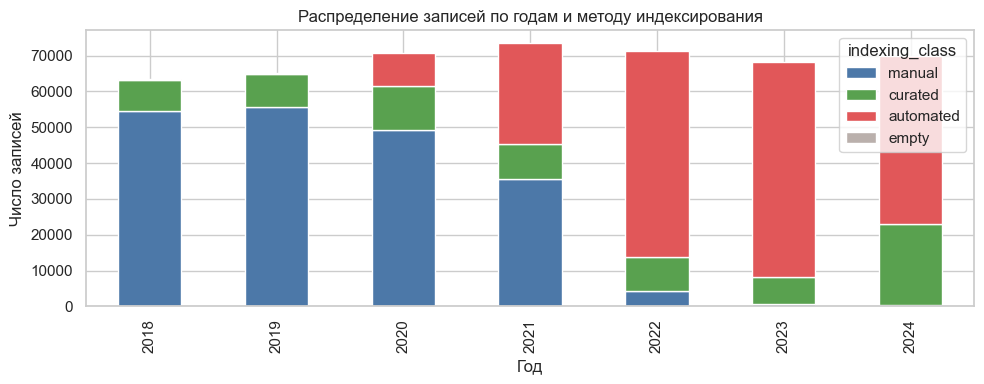


Доля automated по годам:
year
2018    0.004
2019    0.005
2020    0.129
2021    0.383
2022    0.807
2023    0.878
2024    0.671
dtype: float64


In [ ]:
# Распределение записей по годам и классу индексации
ct = (df.groupby(["year", "indexing_class"]).size()
        .unstack(fill_value=0)
        .reindex(columns=["manual", "curated", "automated", "empty"], fill_value=0))
ct.plot(kind="bar", stacked=True, figsize=(10, 4),
        color=["#4C78A8", "#59A14F", "#E15759", "#BAB0AC"])
plt.title("Распределение записей по годам и методу индексирования")
plt.xlabel("Год"); plt.ylabel("Число записей"); plt.legend(title="indexing_class")
plt.tight_layout(); plt.show()
print("\nДоля automated по годам:")
print((ct["automated"] / ct.sum(axis=1)).round(3))

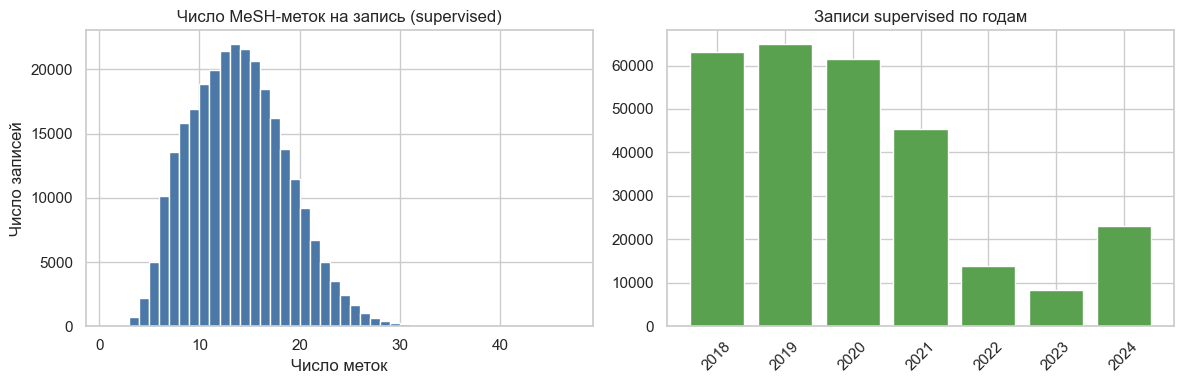

count    279985.00
mean         13.44
std           4.83
min           2.00
25%          10.00
50%          13.00
75%          17.00
max          46.00
Name: mesh_names, dtype: float64


In [ ]:
# Распределение числа меток на запись (на supervised)
n_lbl = df_sup["mesh_names"].str.len()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(n_lbl, bins=range(1, n_lbl.max() + 2),
             color="#4C78A8", edgecolor="white")
axes[0].set_title("Число MeSH-меток на запись (supervised)")
axes[0].set_xlabel("Число меток"); axes[0].set_ylabel("Число записей")

yc = df_sup["year"].value_counts().sort_index()
axes[1].bar(yc.index.astype(str), yc.values, color="#59A14F")
axes[1].set_title("Записи supervised по годам")
plt.setp(axes[1].get_xticklabels(), rotation=45)
plt.tight_layout(); plt.show()
print(n_lbl.describe().round(2))

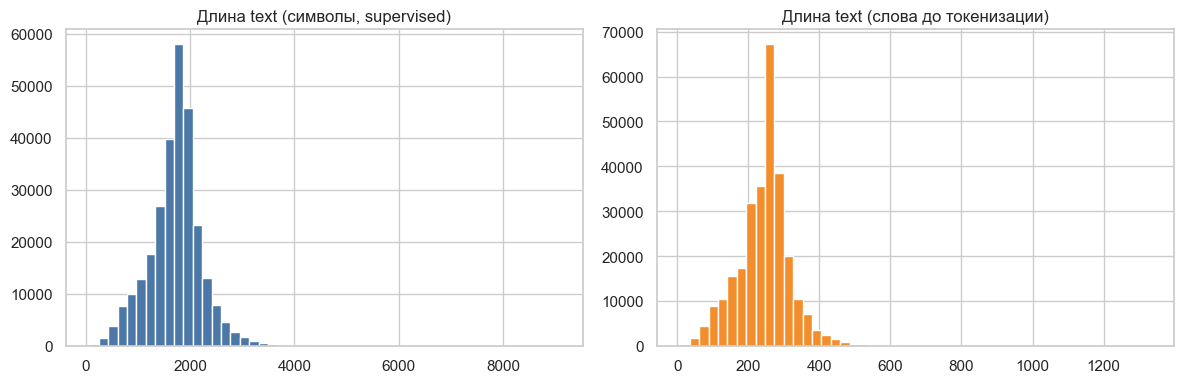

       text_chars  text_tokens_raw
count    279985.0         279985.0
mean       1719.0            245.6
std         525.4             77.2
min          66.0              9.0
50%        1754.0            254.0
75%        1979.0            282.0
90%        2281.0            326.0
95%        2525.0            364.0
99%        3121.0            456.0
max        9081.0           1332.0


In [ ]:
# Длина текстов
df_sup["text_chars"]  = df_sup["text"].str.len()
df_sup["text_tokens_raw"] = df_sup["text"].str.split().apply(len)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df_sup["text_chars"], bins=50, color="#4C78A8", edgecolor="white")
axes[0].set_title("Длина text (символы, supervised)")
axes[1].hist(df_sup["text_tokens_raw"], bins=50, color="#F28E2B", edgecolor="white")
axes[1].set_title("Длина text (слова до токенизации)")
plt.tight_layout(); plt.show()
print(df_sup[["text_chars", "text_tokens_raw"]]
        .describe(percentiles=[.5, .75, .9, .95, .99]).round(1))

In [ ]:
# Несколько примеров записей
for i in df_sup.sample(2, random_state=CONFIG["seed"]).index:
    r = df_sup.loc[i]
    print(f"PMID {r['pmid']} | {r['year']} | {r['journal'][:60]} | indexing={r['indexing_class']}")
    print("TITLE:", r['title'][:200])
    print("ABS:  ", r['abstract'][:300], "...")
    names = r['mesh_names'][:7]
    print("MeSH (имена, первые 7):", names,
          ("..." if len(r['mesh_names']) > 7 else ""))
    print("-" * 80)

PMID 36995033 | 2024 | Orbit (Amsterdam, Netherlands) | indexing=curated
TITLE: Disseminated thrombosis of the internal jugular vein, superior ophthalmic vein and cavernous sinus as the primary manifestation of occult malignancy: a case report.
ABS:   Internal jugular vein (IJV) thrombosis is a life-threatening condition most often associated with local risk factors such as head or neck infection or central venous catheterisation. Underlying malignancy is a rare but important aetiology to consider in patients presenting with spontaneous IJV throm ...
MeSH (имена, первые 7): ['Humans', 'Jugular Veins', 'Carcinoma, Squamous Cell', 'Venous Thrombosis', 'Male', 'Cavernous Sinus', 'Tomography, X-Ray Computed'] ...
--------------------------------------------------------------------------------
PMID 29374578 | 2018 | Hellenic journal of cardiology : HJC = Hellenike kardiologik | indexing=manual
TITLE: Mean Aortic pressure gradient and global longitudinal strain recovery after transcatheter a

### Выводы по EDA

1. Корпус после очистки достаточно большой: **482 061** записей для word2vec и **279 985** записей для supervised-классификации. Это позволяет обучать доменные эмбеддинги на более широком текстовом материале, чем доступен для чистого supervised benchmark.
2. Доля `Automated` существенно меняется по годам: **0.4–0.5%** в 2018–2019, **12.9%** в 2020, **38.3%** в 2021, **80.7%** в 2022, **87.8%** в 2023 и **67.1%** в 2024. Поэтому исключение automated-записей из supervised-части заметно уменьшает объём свежих данных, но повышает надёжность labels.
3. В supervised-корпусе на одну запись приходится в среднем **13.44** MeSH-дескриптора, медиана — **13**, максимум — **46**. Это подтверждает многометочный характер задачи.
4. Средняя длина текста составляет около **245.6** грубых токенов, медиана — **254**, 99-й перцентиль — **456** токенов. Следовательно, `max_seq_len=256` не является нейтральным параметром: он обрезает существенную часть длинных документов и должен рассматриваться как вычислительный компромисс.
5. Распределение меток ожидаемо имеет long-tail-структуру. Поэтому основная метрика — **micro-F1**, а macro-F1 используется как дополнительная характеристика качества на менее частых метках.


---
## 5. Whitelist меток на основе MeSH-онтологии C14

### 5.1. Почему используется MeSH C14

Для отбора целевых рубрик используется ветвь **MeSH C14 — Cardiovascular Diseases**. Это формальный раздел медицинской онтологии MeSH, который объединяет заболевания сердечно-сосудистой системы и связанные с ними патологические состояния.

Такой выбор делает пространство меток воспроизводимым: рубрики определяются через официальную иерархию MeSH. Это важно для supervised-задачи, потому что модель обучается предсказывать стандартизированные медицинские дескрипторы.

При этом C14 следует понимать как широкую область **cardiovascular diseases**, а не как узкую клиническую кардиологию. В неё могут входить сосудистые, цереброваскулярные и смежные состояния, если они формально относятся к данной ветви MeSH.

### 5.2. Проверка `mtrees.bin`

Код скачивает или берёт из кэша файл `mtrees.bin`. Перед использованием выполняется проверка, что файл похож на настоящий MeSH tree file: в нём должны быть тысячи строк с `;` и должна присутствовать ветвь `C14`. Это защищает от ситуации, когда вместо данных скачалась HTML-страница или короткая заглушка.

Данный файл валиден: **64 883** строки дерева, **30 954** уникальных дескриптора, **469** имён-потомков C14.

### 5.3. Правила формирования target space

- Используются только MeSH Descriptor names из C14-потомков (`tree_number.startswith("C14.")`).
- Корневой узел `C14` не включается: он слишком общий и частично совпадает с правилом отбора корпуса.
- Qualifiers и Supplemental Concept Records не используются как target labels.
- Финальный whitelist строится только по train-части после split, чтобы validation/test не влияли на выбор целевых меток.
- Основной эксперимент проводится на **W50**; W100 формируется как потенциальный расширенный вариант, но в данной реализации модели обучаются на W50.


In [ ]:
import urllib.request
from urllib.error import URLError, HTTPError

def looks_like_mtrees(data: bytes) -> bool:
    """Проверяем, что скачался настоящий mtrees, а не HTML-страница/заглушка."""
    head = data[:2000].decode("utf-8", errors="ignore").lower()
    if "<html" in head or "<!doctype" in head:
        return False

    text = data.decode("utf-8", errors="replace").splitlines()
    semi_lines = [line for line in text if ";" in line]

    # В настоящем mtrees должны быть тысячи строк и хотя бы одна ветка C14.
    return len(semi_lines) > 1000 and any(";C14" in line for line in semi_lines)

def download_mesh_trees(out_path: Path) -> Path:
    """Скачиваем валидный mtreesYYYY.bin из годового архива NLM."""
    if out_path.exists():
        data = out_path.read_bytes()
        if looks_like_mtrees(data):
            print(f"[cache] валидный mtrees уже скачан: {out_path}")
            return out_path
        else:
            print(f"[cache] удаляю невалидный mtrees: {out_path} ({out_path.stat().st_size} bytes)")
            out_path.unlink()

    candidates = [
        "https://nlmpubs.nlm.nih.gov/projects/mesh/2025/meshtrees/mtrees2025.bin",
        "https://nlmpubs.nlm.nih.gov/projects/mesh/2024/meshtrees/mtrees2024.bin",
        "https://nlmpubs.nlm.nih.gov/projects/mesh/2023/meshtrees/mtrees2023.bin",
    ]

    last_err = None

    for url in candidates:
        try:
            print("Download:", url)
            req = urllib.request.Request(
                url,
                headers={"User-Agent": CONFIG["entrez_tool"]}
            )

            with urllib.request.urlopen(req, timeout=60) as r:
                data = r.read()

            if not looks_like_mtrees(data):
                print(f"  skipped: файл не похож на полноценный mtrees ({len(data)} bytes)")
                continue

            out_path.write_bytes(data)
            print(f"  ok, {out_path.stat().st_size} bytes")
            return out_path

        except (URLError, HTTPError, TimeoutError) as e:
            last_err = e
            print(f"  failed: {e}")

    raise RuntimeError(f"Не удалось скачать валидный mtrees. Last error: {last_err}")

mtree_path = download_mesh_trees(Path(CONFIG["mesh_tree_file"]))

[cache] валидный mtrees уже скачан: A:\datasets\Course_PUBMED\data\mtrees.bin


In [ ]:
def parse_mesh_trees(path: Path) -> pd.DataFrame:
    """Читаем mtrees.bin → DataFrame со столбцами [name, tree_number]."""
    rows = []
    with open(path, "r", encoding="utf-8", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line or ";" not in line:
                continue
            name, tn = line.rsplit(";", 1)
            rows.append({"name": name.strip(), "tree_number": tn.strip()})
    df = pd.DataFrame(rows)
    return df

mesh_df = parse_mesh_trees(mtree_path)
print(f"Total tree-rows: {len(mesh_df)}")
print(f"Unique descriptors: {mesh_df['name'].nunique()}")

# Все потомки C14, исключая сам корень C14 (=Cardiovascular Diseases)
c14_df = mesh_df[mesh_df["tree_number"].str.startswith("C14.")]
C14_NAMES = sorted(set(c14_df["name"].tolist()))
print(f"\nC14-потомков (имён): {len(C14_NAMES)}")
print("Примеры:", C14_NAMES[:10])

Total tree-rows: 64883
Unique descriptors: 30954

C14-потомков (имён): 469
Примеры: ['22q11 Deletion Syndrome', 'AIDS Arteritis, Central Nervous System', 'Accelerated Idioventricular Rhythm', 'Acute Aortic Syndrome', 'Acute Coronary Syndrome', 'Adams-Stokes Syndrome', 'Alagille Syndrome', 'Andersen Syndrome', 'Aneurysm', 'Aneurysm, Aortic Arch']


**Пояснение.**  
`C14_NAMES` — это множество имён MeSH-дескрипторов, которые находятся в подветвях `C14.*`, без самого корня `Cardiovascular Diseases`. Оно задаёт не финальный набор labels, а **онтологический универсум допустимых cardiovascular-меток**. Финальный whitelist появится позже как пересечение этого универсума с фактическими train-метками и будет отсортирован по частоте.


---
## 6. Токенизация и нормализация текста

### 6.1. Почему нужна специализированная токенизация

Биомедицинские тексты содержат много информативных токенов с цифрами и дефисами: `IL-6`, `TNF-alpha`, `SGLT2`, `COVID-19`, `HFrEF`, `HFpEF`, `miR-197-5p`. Обычная регуляризация, сохраняющая только буквы, разрушила бы часть терминологии и ухудшила бы обучение word2vec.

В коде используется регулярное выражение:

```text
[a-z][a-z0-9]*(?:-[a-z0-9]+)*
```

Перед токенизацией текст приводится к нижнему регистру, а дефис внутри найденных токенов заменяется на подчёркивание: `il-6 → il_6`, `tnf-alpha → tnf_alpha`. Это делает биомедицинские составные термины едиными токенами и не конфликтует с последующим phrase mining.

### 6.2. Диагностика длины

После токенизации считается truncation rate для `max_seq_len=256`. Supervised-корпус имеет среднюю длину **235.3** токена и медиану **241**, но **96 615 из 279 985** supervised-записей длиннее 256 токенов. Это **34.51%** документов.

Следовательно, ограничение длины нельзя назвать несущественным. Это осознанный компромисс между сохранением контекста и ограничениями GPU/RAM. Для более строгого эксперимента стоило бы отдельно проверить `max_seq_len=384` или `512`, но в данной работе выбран вариант 256 как более устойчивый по времени и памяти.


In [ ]:
TOKEN_RE = re.compile(r"[a-z][a-z0-9]*(?:-[a-z0-9]+)*")

def tokenize(text: str) -> list:
    """Биомедицински-ориентированная токенизация.
    Сохраняет 'IL-6', 'TNF-alpha', 'COVID-19', 'miR-197-5p'.
    Дефис заменяется на '_' чтобы не пересекаться с phrase mining."""
    if not text:
        return []
    t = text.lower()
    return [m.group(0).replace("-", "_") for m in TOKEN_RE.finditer(t)]

# Проверка на конкретных биомед-токенах
probe = ("Patients with HFrEF and HFpEF showed elevated IL-6, TNF-alpha. "
         "SGLT2 inhibitors are studied in COVID-19. miR-197-5p was decreased. "
         "STEMI vs NSTEMI outcomes; ACE2 expression.")
print("Probe ->", tokenize(probe))

Probe -> ['patients', 'with', 'hfref', 'and', 'hfpef', 'showed', 'elevated', 'il_6', 'tnf_alpha', 'sglt2', 'inhibitors', 'are', 'studied', 'in', 'covid_19', 'mir_197_5p', 'was', 'decreased', 'stemi', 'vs', 'nstemi', 'outcomes', 'ace2', 'expression']


In [ ]:
# Применяем новую токенизацию ко всем разрезам
df_unsup["tokens"] = df_unsup["text"].apply(tokenize)
df_sup["tokens"]   = df_sup["text"].apply(tokenize)

print("supervised: avg tokens =", round(df_sup["tokens"].str.len().mean(), 1),
      "| median =", int(df_sup["tokens"].str.len().median()))
print("unsupervised: avg tokens =", round(df_unsup["tokens"].str.len().mean(), 1),
      "| median =", int(df_unsup["tokens"].str.len().median()))

# Truncation rate
def truncation_rate(token_lists, max_len):
    n = len(token_lists)
    cut = sum(1 for tt in token_lists if len(tt) > max_len)
    return cut, n, cut / max(1, n)

cut, n, rate = truncation_rate(df_sup["tokens"], CONFIG["max_seq_len"])
print(f"\nTruncation @ max_seq_len={CONFIG['max_seq_len']} (supervised): "
      f"{cut}/{n} = {rate:.2%}")

supervised: avg tokens = 235.3 | median = 241
unsupervised: avg tokens = 236.0 | median = 241

Truncation @ max_seq_len=256 (supervised): 96615/279985 = 34.51%


---
## 7. Разбиение на train / validation / test и формирование whitelist

### 7.1. Логика разбиения

Сначала из supervised-корпуса оставляются только записи, у которых есть хотя бы одна метка из C14-универсума. **20 532** supervised-записи не имеют C14-меток и исключаются; после этого остаётся **259 453** записи. В supervised-корпусе обнаружено **462** C14-метки.

Далее строится бинарная матрица по всему C14-универсуму и применяется **iterative stratification**. Это важно, потому что обычный random split плохо сохраняет распределение редких меток в multi-label задаче.

Формальная цель стратификации — приблизительно сохранить частоты меток:

$$
P_{\mathrm{train}}(y_j = 1) \approx P_{\mathrm{val}}(y_j = 1) \approx P_{\mathrm{test}}(y_j = 1)
$$

для каждой метки $j$.

### 7.2. Формирование W50

После split whitelist строится **только по train**: берутся C14-метки, частота которых в train не ниже `min_label_freq`, затем выбираются top-K по частоте. Активный whitelist — **W50**.

После применения W50 удаляются документы, у которых не осталось ни одной положительной метки из whitelist. Итоговые размеры:

- `Train = 143 283`;
- `Validation = 30 388`;
- `Test = 30 265`;
- среднее число положительных W50-меток на train-документ — **1.27**, медиана — **1**.

### 7.3. Leakage-контроль

Whitelist строится по train, threshold подбирается по validation, а модель выбирается по `val_micro_f1_tuned`. При этом в данной реализации часть baseline-ячеек заранее вычисляет test-probabilities для B1/B2, хотя эти значения не используются для выбора гиперпараметров или модели.


In [ ]:
# Определяем universum: пересечение наблюдаемых MeSH с C14
C14_SET = set(C14_NAMES)
df_sup["mesh_c14"] = df_sup["mesh_names"].apply(lambda xs: sorted({n for n in xs if n in C14_SET}))
keep = df_sup["mesh_c14"].apply(len) > 0
print(f"Записей в supervised без C14-меток: {(~keep).sum()} (исключаем)")
df_sup = df_sup[keep].reset_index(drop=True)
print(f"Supervised после фильтра C14: {len(df_sup)}")

universe = sorted({m for mm in df_sup["mesh_c14"] for m in mm})
print(f"|C14-universe в supervised| = {len(universe)}")

Записей в supervised без C14-меток: 20532 (исключаем)
Supervised после фильтра C14: 259453
|C14-universe в supervised| = 462


In [ ]:
from skmultilearn.model_selection import iterative_train_test_split

def make_binary_matrix(label_lists, labels):
    idx = {l: i for i, l in enumerate(labels)}
    out = np.zeros((len(label_lists), len(labels)), dtype=np.int8)
    for i, mm in enumerate(label_lists):
        for m in mm:
            j = idx.get(m)
            if j is not None: out[i, j] = 1
    return out

Y_universe = make_binary_matrix(df_sup["mesh_c14"].tolist(), universe)
X_idx = np.arange(len(df_sup)).reshape(-1, 1)

X_rest, Y_rest, X_test, Y_test = iterative_train_test_split(
    X_idx, Y_universe, test_size=CONFIG["test_size"])
val_frac_of_rest = CONFIG["val_size"] / (1 - CONFIG["test_size"])
X_train, Y_train, X_val, Y_val = iterative_train_test_split(
    X_rest, Y_rest, test_size=val_frac_of_rest)

train_idx = X_train.flatten()
val_idx   = X_val.flatten()
test_idx  = X_test.flatten()

df_train = df_sup.iloc[train_idx].reset_index(drop=True)
df_val   = df_sup.iloc[val_idx].reset_index(drop=True)
df_test  = df_sup.iloc[test_idx].reset_index(drop=True)
print(f"Train: {len(df_train)} | Val: {len(df_val)} | Test: {len(df_test)}")

Train: 182332 | Val: 38570 | Test: 38551


In [ ]:
def build_whitelist_topk(train_labels, universe, top_k, min_freq):
    """Top-K самых частых в train меток, ограниченных universe (С14) и min_freq."""
    flat = [m for mm in train_labels for m in mm if m in universe]
    freq = Counter(flat)
    cand = [m for m, c in freq.most_common() if c >= min_freq]
    return cand[:top_k]

WHITELIST_50  = build_whitelist_topk(df_train["mesh_c14"], C14_SET,
                                     top_k=CONFIG["whitelist_size"],
                                     min_freq=CONFIG["min_label_freq"])
WHITELIST_100 = build_whitelist_topk(df_train["mesh_c14"], C14_SET,
                                     top_k=CONFIG["whitelist_size_alt"],
                                     min_freq=CONFIG["min_label_freq"])

print(f"W50:  {len(WHITELIST_50)} меток")
print(f"W100: {len(WHITELIST_100)} меток")
print("\nW50 первые 15:", WHITELIST_50[:15])

# Активный whitelist для основных экспериментов
WHITELIST = WHITELIST_50
print(f"\nАктивный whitelist для экспериментов: W{len(WHITELIST)}")

W50:  50 меток
W100: 100 меток

W50 первые 15: ['Stroke', 'Hypertension', 'Heart Failure', 'Myocardial Infarction', 'Coronary Artery Disease', 'Atrial Fibrillation', 'Brain Ischemia', 'Atherosclerosis', 'Thrombosis', 'Reperfusion Injury', 'Multiple Myeloma', 'Heart Defects, Congenital', 'Ischemic Stroke', 'Heart Diseases', 'Diabetic Retinopathy']

Активный whitelist для экспериментов: W50


In [ ]:
def multi_hot(label_lists, whitelist):
    idx = {l: i for i, l in enumerate(whitelist)}
    Y = np.zeros((len(label_lists), len(whitelist)), dtype=np.float32)
    for r, mm in enumerate(label_lists):
        for m in mm:
            j = idx.get(m)
            if j is not None: Y[r, j] = 1.0
    return Y

def apply_whitelist(d, whitelist):
    Y = multi_hot(d["mesh_c14"], whitelist)
    keep = Y.sum(axis=1) > 0
    return d[keep].reset_index(drop=True), Y[keep]

df_train, Y_train_final = apply_whitelist(df_train, WHITELIST)
df_val,   Y_val_final   = apply_whitelist(df_val,   WHITELIST)
df_test,  Y_test_final  = apply_whitelist(df_test,  WHITELIST)
print("После применения whitelist (минимум 1 положительная метка из C14):")
print(f"  Train={len(df_train)} | Val={len(df_val)} | Test={len(df_test)}")
print(f"  Positives/doc (train): mean={Y_train_final.sum(1).mean():.2f}, "
      f"median={int(np.median(Y_train_final.sum(1)))}")

После применения whitelist (минимум 1 положительная метка из C14):
  Train=143283 | Val=30388 | Test=30265
  Positives/doc (train): mean=1.27, median=1


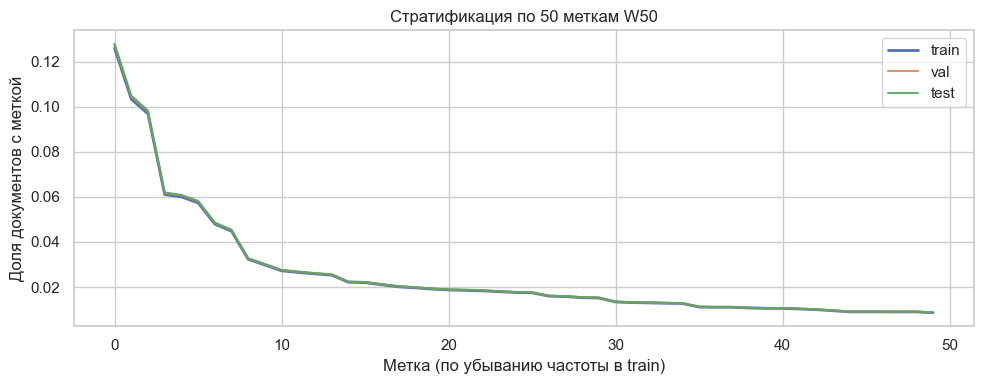

|train-test| drift по частотам: 0.0004


In [ ]:
# Диагностика стратификации
ft = Y_train_final.mean(0); fv = Y_val_final.mean(0); fe = Y_test_final.mean(0)
plt.figure(figsize=(10, 4))
x = np.arange(len(WHITELIST))
plt.plot(x, ft, label="train", lw=2)
plt.plot(x, fv, label="val", lw=1.5, alpha=.9)
plt.plot(x, fe, label="test", lw=1.5, alpha=.9)
plt.xlabel("Метка (по убыванию частоты в train)")
plt.ylabel("Доля документов с меткой")
plt.title(f"Стратификация по {len(WHITELIST)} меткам W{len(WHITELIST)}")
plt.legend(); plt.tight_layout(); plt.show()
print(f"|train-test| drift по частотам: {np.abs(ft-fe).mean():.4f}")

**Вывод по разделу 7.**  
Разбиение выполнено как multilabel iterative stratification. Диагностический график показывает близкие частоты W50-меток в train, validation и test; средний `|train-test|` drift по частотам равен **0.0004**, что подтверждает качество стратификации. Whitelist W50 построен только по train-части, поэтому validation/test не влияют на выбор целевого пространства меток.


---
## 8. Обучение word2vec на расширенном unsupervised-корпусе

### 8.1. Зачем используется расширенный корпус

Главная задача word2vec — выучить устойчивые распределённые представления терминов. Для этого важен объём текстов, а не надёжность MeSH-labels. Поэтому word2vec обучается не только на supervised-train, но и на расширенной unsupervised-части, включая automated-записи.

Чтобы снизить риск утечки, из unsupervised-корпуса исключаются PMID документов из validation и test. Итого:

- `train_sentences = 143 283`;
- `unsup_for_w2v = 421 408` документов;
- phrase mining обучается только на supervised-train, затем детерминированно применяется к train/validation/test и unsupervised-текстам.

### 8.2. Phrase mining

`Phrases` и `Phraser` используются для объединения устойчивых биграмм, например `abdominal_aorta`, `abcd2_score`, `abbott_vascular`. Это помогает word2vec рассматривать частые медицинские словосочетания как цельные токены.

### 8.3. CBOW vs Skip-gram

Оба варианта word2vec обучаются с одинаковыми базовыми параметрами: размерность **200**, окно **5**, `min_count=5`, `negative=10`, **10 эпох**. Выбор между CBOW и Skip-gram делается по downstream-метрике на задаче `AvgW2V + LogisticRegression` на validation.


In [ ]:
from gensim.models import Word2Vec
from gensim.models.phrases import Phrases, Phraser

# 1) Phrase mining — на supervised-train
phrases_train = Phrases(df_train["tokens"].tolist(),
                        min_count=15, threshold=10.0)
bigram = Phraser(phrases_train)

def apply_bigram(toks_list):
    return [bigram[t] for t in toks_list]

train_sentences = apply_bigram(df_train["tokens"].tolist())
val_sentences   = apply_bigram(df_val["tokens"].tolist())
test_sentences  = apply_bigram(df_test["tokens"].tolist())

# 2) Расширенный unsup-корпус: всё, кроме val/test PMID-ов
val_pmids  = set(df_val["pmid"]); test_pmids = set(df_test["pmid"])
df_unsup_for_w2v = df_unsup[~df_unsup["pmid"].isin(val_pmids | test_pmids)].copy()
unsup_sentences = apply_bigram(df_unsup_for_w2v["tokens"].tolist())
print(f"|train_sentences|     = {len(train_sentences)}")
print(f"|unsup_for_w2v|       = {len(unsup_sentences)}  "
      f"(supervised-train + automated, без val/test PMID-ов)")

# Несколько примеров биграмм
biexamples = sorted({tok for s in train_sentences[:1000] for tok in s if "_" in tok})[:20]
print("Примеры биграмм:", biexamples)

|train_sentences|     = 143283
|unsup_for_w2v|       = 421408  (supervised-train + automated, без val/test PMID-ов)
Примеры биграмм: ['a2_lp_pla2', 'a_band', 'a_cross_sectional', 'a_double_edged', 'a_et', 'a_life_threatening', 'aaa_rupture', 'aab_induced', 'aab_positive', 'aav9_mediated', 'aav_9', 'aav_pcsk9dy', 'ab_induced', 'abbott_vascular', 'abca1_abcg1', 'abcd2_score', 'abcd3_i', 'abdominal_aorta', 'abdominal_aortic', 'abdominal_obesity']


In [ ]:
def train_w2v(sents, sg, cfg):
    return Word2Vec(
        sentences=sents,
        vector_size=cfg["w2v_size"],
        window=cfg["w2v_window"],
        min_count=cfg["w2v_min_count"],
        sg=sg, negative=10,
        workers=cfg["w2v_workers"],
        epochs=cfg["w2v_epochs"],
        seed=cfg["seed"],
    )

print("Обучение CBOW на расширенном unsup-корпусе...")
w2v_cbow = train_w2v(unsup_sentences, sg=0, cfg=CONFIG)
print("Обучение Skip-gram на расширенном unsup-корпусе...")
w2v_sg   = train_w2v(unsup_sentences, sg=1, cfg=CONFIG)

def w2v_stats(m, name):
    n = len(m.wv)
    print(f"[{name}] vocab={n} | dim={m.wv.vector_size}")

w2v_stats(w2v_cbow, "CBOW"); w2v_stats(w2v_sg, "Skip-gram")
w2v_cbow.save(str(Path(CONFIG["models_dir"]) / "w2v_cbow.model"))
w2v_sg.save(str(Path(CONFIG["models_dir"]) / "w2v_sg.model"))

Обучение CBOW на расширенном unsup-корпусе...
Обучение Skip-gram на расширенном unsup-корпусе...
[CBOW] vocab=163000 | dim=200
[Skip-gram] vocab=163000 | dim=200


### 8.4. Intrinsic sanity-check: ближайшие соседи

Ближайшие соседи не являются основной метрикой качества, но служат sanity-check: если для терминов `myocardial_infarction`, `heart_failure`, `atrial_fibrillation`, `hypertension`, `stroke` находятся семантически близкие медицинские слова и словосочетания, значит word2vec выучил предметную структуру корпуса хотя бы на качественном уровне.

Эта проверка не заменяет downstream-оценку: красивые nearest neighbors не гарантируют высокий F1 в задаче рубрицирования.


In [ ]:
PROBE_TERMS = [
    "myocardial_infarction", "heart_failure", "atrial_fibrillation",
    "hypertension", "stroke", "cholesterol", "arrhythmia", "il_6", "covid_19",
]

def probe_nn(model, terms, topn=6):
    out = {}
    for t in terms:
        if t in model.wv:
            out[t] = model.wv.most_similar(t, topn=topn)
        else:
            alt = t.split("_")[0]
            if alt in model.wv:
                out[f"{t} (fallback {alt})"] = model.wv.most_similar(alt, topn=topn)
            else:
                out[t] = []
    return out

def print_nn(d, name):
    print(f"=== {name} ===")
    for t, nn in d.items():
        line = ", ".join(f"{w}({s:.2f})" for w, s in nn[:5])
        print(f"  {t:38s} → {line}")

print_nn(probe_nn(w2v_cbow, PROBE_TERMS), "CBOW"); print()
print_nn(probe_nn(w2v_sg,   PROBE_TERMS), "Skip-gram")

=== CBOW ===
  myocardial_infarction                  → mi(0.76), myocardial_infraction(0.71), myocardial_infarctions(0.64), reinfarction(0.56), re_infarction(0.54)
  heart_failure                          → hf(0.79), chf(0.64), hfref(0.58), hfpef(0.57), dilated_cardiomyopathy(0.56)
  atrial_fibrillation                    → af(0.77), afib(0.64), non_paroxysmal(0.63), device_detected(0.62), atrial_arrhythmias(0.62)
  hypertension                           → hypertension_htn(0.80), htn(0.77), arterial_hypertension(0.76), hypertensive(0.67), obesity(0.66)
  stroke                                 → ischemic_stroke(0.80), ischaemic_stroke(0.78), stoke(0.75), stroke_ais(0.68), strokes(0.67)
  cholesterol                            → ldl(0.76), ldl_cholesterol(0.76), triglyceride(0.74), triglyceride_tg(0.71), triglycerides(0.69)
  arrhythmia                             → arrhythmias(0.85), arrythmia(0.77), dysrhythmia(0.75), tachyarrhythmia(0.74), tachyarrhythmias(0.73)
  il_6               

### 8.5. Downstream-сравнение CBOW и Skip-gram

Для каждого варианта эмбеддингов строится простой документный вектор как среднее word2vec-векторов токенов:

$$
\mathbf{x}_{\mathrm{doc}} =
\frac{1}{|T_{\mathrm{doc}}|}
\sum_{t \in T_{\mathrm{doc}}} \mathbf{v}_t
$$

Затем обучается одинаковый `OneVsRest LogisticRegression`, а глобальный threshold подбирается по validation. Итого:

- **CBOW**: `val_micro_f1_tuned = 0.6894`, threshold `0.27`;
- **Skip-gram**: `val_micro_f1_tuned = 0.6704`, threshold `0.26`.

Поэтому основным word2vec-вариантом выбран **CBOW** с размерностью 200 и словарём **163 000** токенов.


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score

def doc_mean_vec(tokens, wv, dim):
    vecs = [wv[t] for t in tokens if t in wv]
    if not vecs: return np.zeros(dim, dtype=np.float32)
    return np.mean(vecs, axis=0).astype(np.float32)

def avg_w2v_matrix(sents, wv):
    dim = wv.vector_size
    return np.vstack([doc_mean_vec(s, wv, dim) for s in sents])

def tune_threshold_micro(y_true, y_prob, grid=None):
    if grid is None: grid = np.linspace(0.05, 0.6, 56)
    best_t, best_f1 = 0.5, -1.0
    for t in grid:
        f1 = f1_score(y_true, (y_prob >= t).astype(np.int8),
                      average="micro", zero_division=0)
        if f1 > best_f1: best_f1, best_t = f1, t
    return float(best_t), float(best_f1)

def downstream_w2v_compare(w2v, name):
    Xtr = avg_w2v_matrix(train_sentences, w2v.wv)
    Xva = avg_w2v_matrix(val_sentences,   w2v.wv)
    clf = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=1.0), n_jobs=1)
    clf.fit(Xtr, Y_train_final)
    prob_va = np.vstack([est.predict_proba(Xva)[:, 1] for est in clf.estimators_]).T
    thr, f1 = tune_threshold_micro(Y_val_final, prob_va)
    print(f"[{name}]  val_micro_f1_tuned = {f1:.4f} (thr={thr:.2f})")
    return f1

print("Сравнение CBOW vs Skip-gram через downstream val-F1:")
f1_cbow = downstream_w2v_compare(w2v_cbow, "CBOW")
f1_sg   = downstream_w2v_compare(w2v_sg,   "Skip-gram")

if f1_sg >= f1_cbow:
    W2V_MAIN = w2v_sg;   W2V_NAME = "Skip-gram"
else:
    W2V_MAIN = w2v_cbow; W2V_NAME = "CBOW"
print(f"\n>>> Выбран {W2V_NAME} как W2V_MAIN (val-F1 = {max(f1_sg, f1_cbow):.4f})")
print(f"    dim = {W2V_MAIN.wv.vector_size}, |vocab| = {len(W2V_MAIN.wv)}")

Сравнение CBOW vs Skip-gram через downstream val-F1:
[CBOW]  val_micro_f1_tuned = 0.6894 (thr=0.27)
[Skip-gram]  val_micro_f1_tuned = 0.6704 (thr=0.26)

>>> Выбран CBOW как W2V_MAIN (val-F1 = 0.6894)
    dim = 200, |vocab| = 163000


---
## 9. Диагностика покрытия словаря word2vec

После выбора CBOW проверяется, насколько словарь word2vec покрывает токены train/validation/test.

Используются две метрики:

- **type coverage** — доля уникальных токенов, которые присутствуют в словаре;
- **token coverage** — доля всех токенов с учётом частоты, которые присутствуют в словаре.

token coverage высокий: **99.36%** на train, **99.06%** на validation и **99.05%** на test. Type coverage ниже: **49.69%** на train, около **70%** на validation/test. Это нормальная картина для биомедицинского корпуса: много уникальных редких терминов, но основная масса токеноупотреблений покрыта словарём.

Следовательно, OOV-проблема существует на уровне редких типов, но не является главным источником потерь на уровне частотных токенов.


In [ ]:
def coverage_stats(sents, wv, name):
    types_seen, total_tokens, in_vocab_tokens = set(), 0, 0
    for s in sents:
        for tok in s:
            types_seen.add(tok)
            total_tokens += 1
            if tok in wv: in_vocab_tokens += 1
    types_in = sum(1 for t in types_seen if t in wv)
    print(f"[{name}] types_total={len(types_seen)}, "
          f"types_in_vocab={types_in} ({types_in / max(1,len(types_seen)):.2%}); "
          f"tokens_total={total_tokens}, in_vocab={in_vocab_tokens} "
          f"({in_vocab_tokens / max(1,total_tokens):.2%})")

coverage_stats(train_sentences, W2V_MAIN.wv, "train")
coverage_stats(val_sentences,   W2V_MAIN.wv, "val")
coverage_stats(test_sentences,  W2V_MAIN.wv, "test")

[train] types_total=272650, types_in_vocab=135491 (49.69%); tokens_total=30631461, in_vocab=30436137 (99.36%)
[val] types_total=116557, types_in_vocab=82127 (70.46%); tokens_total=6368805, in_vocab=6308862 (99.06%)
[test] types_total=115587, types_in_vocab=80955 (70.04%); tokens_total=6336821, in_vocab=6276551 (99.05%)


---
## 10. Метрики, ориентиры качества и подбор threshold

Задача является multi-label: для каждого документа модель выдаёт вероятность каждой из 50 меток, а затем вероятности бинаризуются по порогу.

В коде используются следующие метрики:

- **micro-F1** — основная метрика выбора модели; агрегирует TP/FP/FN по всем меткам и поэтому устойчивее при дисбалансе;
- **macro-F1** — среднее F1 по меткам, чувствительно к качеству на редких классах;
- **weighted-F1** — среднее по меткам с весами по support;
- **micro-precision** и **micro-recall** — баланс точности и полноты;
- **Hamming loss** — доля ошибочных label-документ решений;
- **subset accuracy** — строгая метрика полного совпадения всех labels документа;
- **LRAP** и **micro-AP** — ранжирующие метрики по вероятностям.

F1 для одной метки определяется как:

$$
F1 = \frac{2PR}{P + R}, \quad
P = \frac{TP}{TP + FP}, \quad
R = \frac{TP}{TP + FN}
$$

Глобальный threshold подбирается функцией `tune_threshold_micro` только на validation. Это важно, потому что в multi-label задаче фиксированный порог 0.5 часто неоптимален.

### Ориентиры качества

Поскольку задача решается на специально сформированном наборе PubMed-аннотаций и собственном W50-пространстве MeSH C14-меток, прямое сравнение с внешними работами по численным значениям метрик ограничено: состав корпуса, набор labels, годы публикаций и правила фильтрации отличаются. Поэтому в работе используются внутренние ориентиры качества. Слабым уровнем считается качество тривиальных baseline-моделей, которые не используют содержательные текстовые признаки: `All-Zero`, `Most-Frequent` и `TopK-Frequent`. Они задают нижнюю границу и показывают, какой результат можно получить только за счёт дисбаланса меток.

Средним ориентиром считается модель `AvgW2V + Logistic Regression`, так как она использует обученные word2vec-векторы, но представляет документ простым усреднением токенов и не учитывает порядок слов, локальные терминологические сочетания и структуру текста. Сильным практическим ориентиром в данной работе выбран `TF-IDF + One-vs-Rest Logistic Regression`, поскольку TF-IDF является устойчивым классическим подходом для текстовой классификации, хорошо работает на разреженных медицинских терминах и не требует сложной нейросетевой архитектуры. Поэтому нейросетевые модели на основе word2vec считаются успешными только в том случае, если они превосходят tuned TF-IDF baseline на validation и затем подтверждают близкое качество на test.

In [ ]:
from sklearn.metrics import (
    f1_score, precision_score, recall_score, hamming_loss,
    accuracy_score, label_ranking_average_precision_score,
    average_precision_score,
)

def eval_multilabel(y_true, y_pred_bin, y_pred_prob=None, name="model"):
    res = {
        "model":         name,
        "micro_f1":      f1_score(y_true, y_pred_bin, average="micro",    zero_division=0),
        "macro_f1":      f1_score(y_true, y_pred_bin, average="macro",    zero_division=0),
        "weighted_f1":   f1_score(y_true, y_pred_bin, average="weighted", zero_division=0),
        "micro_prec":    precision_score(y_true, y_pred_bin, average="micro", zero_division=0),
        "micro_rec":     recall_score(   y_true, y_pred_bin, average="micro", zero_division=0),
        "hamming_loss":  hamming_loss(y_true, y_pred_bin),
        "subset_acc":    accuracy_score(y_true, y_pred_bin),
    }
    if y_pred_prob is not None:
        try:
            res["lrap"]     = label_ranking_average_precision_score(y_true, y_pred_prob)
            res["micro_ap"] = average_precision_score(y_true, y_pred_prob, average="micro")
        except ValueError:
            res["lrap"] = float("nan"); res["micro_ap"] = float("nan")
    return res

RESULTS = []   # глобальный накопитель

---
## 11. Бейзлайны

Бейзлайны нужны, чтобы интерпретировать качество нейросетей не изолированно, а относительно нескольких уровней сложности: тривиальных правил, простого использования word2vec и сильного классического TF-IDF-подхода.

| Ид. | Модель | Назначение |
|---|---|---|
| B0a | All-Zero | нижняя граница: не предсказывать ни одной метки |
| B0b | Most-Frequent | всегда предсказывать самую частую train-метку |
| B0c | TopK-Frequent | предсказывать `k` самых частых меток, где `k` равно среднему числу labels на документ |
| B1 | TF-IDF + OvR Logistic Regression | сильный классический текстовый baseline |
| B1t | tuned TF-IDF + OvR Logistic Regression | holdout-подбор `ngram_range`, `min_df`, `max_features`, `C` |
| B2 | AvgW2V + OvR Logistic Regression | проверка, достаточно ли простого усреднения word2vec |

Все модели сравниваются по `val_micro_f1_tuned`, то есть micro-F1 на validation после подбора глобального threshold. Test-метрики используются для финальной отчётности, но не для выбора гиперпараметров.


In [ ]:
# B0: тривиальные бейзлайны
def trivial_baselines(Y_train, Y_val, whitelist):
    n_lbl = Y_train.shape[1]
    avg_per_doc = max(1, int(round(Y_train.sum(1).mean())))
    train_label_freq = Y_train.sum(0)
    most_freq_idx = int(np.argmax(train_label_freq))
    topk_idx = list(np.argsort(-train_label_freq)[:avg_per_doc])

    rows = []
    # all-zero
    pred = np.zeros_like(Y_val)
    rows.append({"name": "B0a_AllZero",
                 **eval_multilabel(Y_val, pred, name="B0a_AllZero")})
    # most-frequent
    pred = np.zeros_like(Y_val); pred[:, most_freq_idx] = 1
    rows.append({"name": "B0b_MostFreq",
                 **eval_multilabel(Y_val, pred, name="B0b_MostFreq")})
    # top-k
    pred = np.zeros_like(Y_val); pred[:, topk_idx] = 1
    rows.append({"name": f"B0c_Top{avg_per_doc}",
                 **eval_multilabel(Y_val, pred, name=f"B0c_Top{avg_per_doc}")})
    return rows, avg_per_doc, most_freq_idx, topk_idx

trivial_rows, k_avg, mf_idx, topk_idx = trivial_baselines(
    Y_train_final, Y_val_final, WHITELIST)
for r in trivial_rows:
    name = r["name"]; v = r
    v["val_micro_f1_tuned"] = v["micro_f1"]
    v["threshold"] = float("nan"); v["train_time_s"] = 0.0
    v["model"] = name
    print(f"[{name}] val micro-F1 = {v['micro_f1']:.4f}")
    RESULTS.append(v)
print(f"\n(top-k avg labels per train doc: k={k_avg}; "
      f"most freq = '{WHITELIST[mf_idx]}')")

[B0a_AllZero] val micro-F1 = 0.0000
[B0b_MostFreq] val micro-F1 = 0.1115
[B0c_Top1] val micro-F1 = 0.1115

(top-k avg labels per train doc: k=1; most freq = 'Stroke')


In [ ]:
# B1: TF-IDF + OvR LR
import time as _t
from sklearn.feature_extraction.text import TfidfVectorizer

def fit_b1(C=1.0, ngram=(1, 2), min_df=5, max_features=50_000):
    tfidf = TfidfVectorizer(lowercase=True, ngram_range=ngram,
                             min_df=min_df, max_df=0.95,
                             max_features=max_features, sublinear_tf=True)
    Xtr = tfidf.fit_transform(df_train["text"])
    Xva = tfidf.transform(df_val["text"])
    Xte = tfidf.transform(df_test["text"])
    clf = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=C, solver="liblinear"),
                               n_jobs=1)
    t0 = _t.time(); clf.fit(Xtr, Y_train_final); t_fit = _t.time() - t0
    prob_va = np.vstack([e.predict_proba(Xva)[:, 1] for e in clf.estimators_]).T
    prob_te = np.vstack([e.predict_proba(Xte)[:, 1] for e in clf.estimators_]).T
    thr, f1_va = tune_threshold_micro(Y_val_final, prob_va)
    return {"prob_va": prob_va, "prob_te": prob_te,
            "thr": thr, "val_f1": f1_va, "t_fit": t_fit,
            "tfidf": tfidf, "clf": clf}

b1 = fit_b1()
res_b1 = eval_multilabel(Y_val_final,
                          (b1["prob_va"] >= b1["thr"]).astype(np.int8),
                          b1["prob_va"], name="B1_TFIDF_LR")
res_b1.update({"val_micro_f1_tuned": b1["val_f1"], "threshold": b1["thr"],
               "train_time_s": b1["t_fit"]})
RESULTS.append(res_b1)
print(f"[B1] val_micro_f1_tuned = {b1['val_f1']:.4f} @ thr={b1['thr']:.2f}")

[B1] val_micro_f1_tuned = 0.7823 @ thr=0.20


In [ ]:
# B2: AvgW2V + OvR LR
X_tr_avg = avg_w2v_matrix(train_sentences, W2V_MAIN.wv)
X_va_avg = avg_w2v_matrix(val_sentences,   W2V_MAIN.wv)
X_te_avg = avg_w2v_matrix(test_sentences,  W2V_MAIN.wv)

clf_b2 = OneVsRestClassifier(LogisticRegression(max_iter=1000, C=1.0), n_jobs=1)
t0 = _t.time(); clf_b2.fit(X_tr_avg, Y_train_final); t_b2 = _t.time() - t0
prob_va_b2 = np.vstack([e.predict_proba(X_va_avg)[:, 1] for e in clf_b2.estimators_]).T
prob_te_b2 = np.vstack([e.predict_proba(X_te_avg)[:, 1] for e in clf_b2.estimators_]).T
thr_b2, f1_va_b2 = tune_threshold_micro(Y_val_final, prob_va_b2)

res_b2 = eval_multilabel(Y_val_final,
                          (prob_va_b2 >= thr_b2).astype(np.int8),
                          prob_va_b2, name="B2_AvgW2V_LR")
res_b2.update({"val_micro_f1_tuned": f1_va_b2, "threshold": thr_b2,
               "train_time_s": t_b2})
RESULTS.append(res_b2)
print(f"[B2] val_micro_f1_tuned = {f1_va_b2:.4f} @ thr={thr_b2:.2f}")

[B2] val_micro_f1_tuned = 0.6894 @ thr=0.27


**Промежуточный вывод по бейзлайнам.**

- `B0a_AllZero` даёт `val_micro_f1 = 0.0000`, что ожидаемо: модель не предсказывает положительных labels.
- В W50 среднее число labels на train-документ округляется до `k=1`, поэтому `B0b_MostFreq` и `B0c_Top1` совпадают. Они всегда предсказывают метку **`Stroke`** и дают `val_micro_f1 = 0.1115`.
- `B1_TFIDF_LR` даёт `val_micro_f1_tuned = 0.7823` при threshold `0.20`.
- `B2_AvgW2V_LR` даёт только `val_micro_f1_tuned = 0.6894` при threshold `0.27`.

Главный промежуточный результат: простое усреднение word2vec-векторов заметно проигрывает TF-IDF. Следовательно, дальнейший выигрыш нейросетей нельзя приписывать только самому факту использования word2vec; он связан также с архитектурой, которая учитывает порядок и локальные паттерны токенов.


---
## 12. Подготовка признаков для нейросетевых моделей

Для MLP, TextCNN и BiGRU тексты переводятся в матрицы индексов токенов фиксированной длины:

- форма входа: `(B, T)`, где `B` — batch size, `T = max_seq_len = 256`;
- `0` — `<pad>`;
- `1` — `<unk>`;
- реальные токены начинаются с индекса `2`;
- матрица эмбеддингов имеет форму `(V, D)`, где `D = 200`.

Матрица эмбеддингов имеет размер **(163002, 200)**: 163 000 word2vec-токенов плюс `<pad>` и `<unk>`. Размеры последовательностей после кодирования: train **(143283, 256)**, validation **(30388, 256)**, test **(30265, 256)**. Средние эффективные длины после обрезки/паддинга — примерно **205.5**, **203.1** и **202.9**.


In [ ]:
PAD, UNK = "<pad>", "<unk>"
w2v_vocab = list(W2V_MAIN.wv.key_to_index.keys())
itos = [PAD, UNK] + w2v_vocab
stoi = {w: i for i, w in enumerate(itos)}
V    = len(itos)
D    = W2V_MAIN.wv.vector_size

emb_matrix = np.zeros((V, D), dtype=np.float32)
emb_matrix[stoi[UNK]] = np.random.normal(0, 0.1, size=(D,)).astype(np.float32)
for w in w2v_vocab:
    emb_matrix[stoi[w]] = W2V_MAIN.wv[w]
emb_matrix_t = torch.from_numpy(emb_matrix)
print(f"Embedding matrix: {emb_matrix.shape}")

def encode_with_length(tokens, max_len=CONFIG["max_seq_len"]):
    """Возвращает (ids[max_len], length)."""
    ids = [stoi.get(t, stoi[UNK]) for t in tokens[:max_len]]
    L = len(ids)
    if L < max_len:
        ids = ids + [stoi[PAD]] * (max_len - L)
    return ids, L

def encode_corpus(sents):
    ids_arr, lens_arr = [], []
    for s in sents:
        ids, L = encode_with_length(s)
        ids_arr.append(ids); lens_arr.append(L)
    return (np.array(ids_arr,  dtype=np.int64),
            np.array(lens_arr, dtype=np.int64))

X_tr_ids, L_tr = encode_corpus(train_sentences)
X_va_ids, L_va = encode_corpus(val_sentences)
X_te_ids, L_te = encode_corpus(test_sentences)
print("shapes:", X_tr_ids.shape, X_va_ids.shape, X_te_ids.shape)
print("avg lengths:", L_tr.mean().round(1), L_va.mean().round(1), L_te.mean().round(1))

Embedding matrix: (163002, 200)
shapes: (143283, 256) (30388, 256) (30265, 256)
avg lengths: 205.5 203.1 202.9


In [ ]:
class MLDataset(Dataset):
    def __init__(self, X, L, Y):
        self.X = torch.from_numpy(X).long()
        self.L = torch.from_numpy(L).long()
        self.Y = torch.from_numpy(Y).float()
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.L[i], self.Y[i]

train_ds = MLDataset(X_tr_ids, L_tr, Y_train_final)
val_ds   = MLDataset(X_va_ids, L_va, Y_val_final)
test_ds  = MLDataset(X_te_ids, L_te, Y_test_final)

def make_loaders(bs):
    g = torch.Generator(); g.manual_seed(CONFIG["seed"])
    tl = DataLoader(train_ds, batch_size=bs, shuffle=True,  num_workers=0, generator=g)
    vl = DataLoader(val_ds,   batch_size=bs, shuffle=False, num_workers=0)
    te = DataLoader(test_ds,  batch_size=bs, shuffle=False, num_workers=0)
    return tl, vl, te

---
## 13. Нейросетевые архитектуры и работа с padding

В работе сравниваются три нейросетевые архитектуры на pretrained word2vec-эмбеддингах.

### M1: MLP

Для каждого документа считаются masked mean-pooling и masked max-pooling по эмбеддингам токенов. Эти два вектора конкатенируются и подаются в полносвязную сеть. Модель не учитывает порядок слов, но проверяет, насколько полезны агрегированные dense-признаки.

### M2: TextCNN

TextCNN применяет одномерные свёртки с ядрами `(3, 5, 7)`, чтобы ловить локальные n-граммные паттерны. Важная деталь: после свёрток PAD-позиции маскируются значением `-1e9` перед max-over-time pooling. Это снижает риск того, что bias свёртки создаст искусственно сильную активацию на padding-зоне.

### M3: BiGRU + Attention

BiGRU учитывает порядок токенов в обе стороны. Для корректной обработки переменных длин используется `pack_padded_sequence(enforce_sorted=False)`, поэтому рекуррентная сеть не обучается на искусственных PAD-токенах. Attention также считается с маской, чтобы веса не назначались padding-позициям.

Такое сравнение позволяет разделить три уровня сложности: простая агрегация (`MLP`), локальные паттерны (`TextCNN`) и последовательностная модель с attention (`BiGRU`).


In [ ]:
def make_embedding(pretrained, freeze=False):
    return nn.Embedding.from_pretrained(pretrained, freeze=freeze, padding_idx=0)

class MLP(nn.Module):
    """M1. Concat(mean,max) → FC → ReLU → Dropout → FC."""
    def __init__(self, emb_weight, n_labels, hidden=256, dropout=0.4):
        super().__init__()
        self.emb = make_embedding(emb_weight)
        D = emb_weight.shape[1]
        self.fc1 = nn.Linear(2 * D, hidden)
        self.drop = nn.Dropout(dropout)
        self.fc2 = nn.Linear(hidden, n_labels)
    def forward(self, x, lengths=None):
        mask = (x != 0)
        e = self.emb(x) * mask.unsqueeze(-1).float()
        denom = mask.sum(1, keepdim=True).clamp(min=1).float()
        mean_p = e.sum(1) / denom
        e_for_max = e.masked_fill(~mask.unsqueeze(-1), -1e9)
        max_p, _  = e_for_max.max(1)
        h = torch.cat([mean_p, max_p], dim=-1)
        h = F.relu(self.fc1(h)); h = self.drop(h)
        return self.fc2(h)


class TextCNN(nn.Module):
    """M2. Conv1d (нечётные kernels) → masked max-over-time → FC."""
    def __init__(self, emb_weight, n_labels, n_filters=96,
                 kernel_sizes=(3, 5, 7), dropout=0.4):
        super().__init__()
        self.emb = make_embedding(emb_weight)
        D = emb_weight.shape[1]
        self.convs = nn.ModuleList([
            nn.Conv1d(D, n_filters, kernel_size=k, padding=k // 2)
            for k in kernel_sizes
        ])
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(n_filters * len(kernel_sizes), n_labels)
    def forward(self, x, lengths=None):
        mask = (x != 0)                                      # (B, T)
        e = self.emb(x).transpose(1, 2)                      # (B, D, T)
        feats = []
        for conv in self.convs:
            c = F.relu(conv(e))                              # (B, F, T_out=T)
            # Маскируем PAD-позиции перед max-pool
            c = c.masked_fill(~mask.unsqueeze(1), -1e9)
            p = F.max_pool1d(c, kernel_size=c.size(-1)).squeeze(-1)
            feats.append(p)
        h = torch.cat(feats, dim=-1)
        h = self.drop(h)
        return self.fc(h)


class BiGRUAttn(nn.Module):
    """M3. PackedSeq → BiGRU → masked attention → FC."""
    def __init__(self, emb_weight, n_labels, hidden=128, dropout=0.4):
        super().__init__()
        self.emb = make_embedding(emb_weight)
        D = emb_weight.shape[1]
        self.gru = nn.GRU(D, hidden, batch_first=True, bidirectional=True)
        self.attn = nn.Linear(2 * hidden, 1)
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(2 * hidden, n_labels)
    def forward(self, x, lengths):
        mask = (x != 0)
        e = self.emb(x)
        # PAD-aware GRU
        lengths_cpu = lengths.detach().cpu().clamp(min=1)
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths_cpu, batch_first=True,
                                                    enforce_sorted=False)
        out_packed, _ = self.gru(packed)
        h, _ = nn.utils.rnn.pad_packed_sequence(out_packed, batch_first=True,
                                                 total_length=x.size(1))
        a = self.attn(h).squeeze(-1)                         # (B, T)
        a = a.masked_fill(~mask, -1e9)
        w = torch.softmax(a, dim=-1).unsqueeze(-1)
        c = (h * w).sum(1)
        c = self.drop(c)
        return self.fc(c)

---
## 14. Универсальный train loop

`train_model` реализует единый цикл обучения для нейросетей:

1. обучение на train через `BCEWithLogitsLoss`;
2. расчёт вероятностей на validation;
3. подбор глобального threshold на validation;
4. вычисление `val_micro_f1_tuned`;
5. сохранение лучшего checkpoint по validation;
6. early stopping при отсутствии улучшения.

Критерий выбора эпохи — именно `val_micro_f1_tuned`, а не F1 при фиксированном threshold 0.5. В multi-label классификации оптимальный порог часто ниже или выше 0.5.

Параметр `pos_weight` поддерживается отдельно и используется как абляционный эксперимент для борьбы с дисбалансом labels. Он не включается автоматически в основную модель, потому что может повышать recall ценой precision и ухудшать micro-F1.


In [ ]:
def make_pos_weight(Y, cap=10.0):
    """pos_weight = neg/pos для каждого класса, capped."""
    pos = Y.sum(0)
    neg = Y.shape[0] - pos
    pw = neg / np.maximum(pos, 1.0)
    return torch.tensor(np.clip(pw, 1.0, cap), dtype=torch.float32)

def _make_optimizer(model, lr, wd):
    emb_params, other = [], []
    for n, p in model.named_parameters():
        (emb_params if n.startswith("emb.") else other).append(p)
    return torch.optim.AdamW([
        {"params": emb_params, "lr": lr * 0.1, "weight_decay": 0.0},
        {"params": other,      "lr": lr,       "weight_decay": wd},
    ])

def _epoch(model, loader, opt=None, criterion=None, device=DEVICE):
    is_train = opt is not None
    model.train() if is_train else model.eval()
    total, probs, truths = 0.0, [], []
    for xb, lb, yb in loader:
        xb, lb, yb = xb.to(device), lb.to(device), yb.to(device)
        with torch.set_grad_enabled(is_train):
            logits = model(xb, lb)
            loss = criterion(logits, yb)
            if is_train:
                opt.zero_grad(); loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 2.0)
                opt.step()
        total += loss.item() * xb.size(0)
        probs.append(torch.sigmoid(logits).detach().cpu().numpy())
        truths.append(yb.detach().cpu().numpy())
    probs  = np.concatenate(probs); truths = np.concatenate(truths)
    return total / len(loader.dataset), probs, truths

In [ ]:
def train_model(model_cls, name, cfg=CONFIG, evaluate_test=False,
                 use_pos_weight=False, **kwargs):
    """
    Обучение нейросетевой модели.

    evaluate_test=False (по умолчанию):
        train + val цикл, early stopping по val_micro_f1_tuned, никакого test.
    evaluate_test=True:
        дополнительно после обучения один раз считается test-метрика.
    """
    model = model_cls(emb_matrix_t, n_labels=len(WHITELIST), **kwargs).to(DEVICE)
    opt = _make_optimizer(model, cfg["lr"], cfg["weight_decay"])
    if use_pos_weight:
        pw = make_pos_weight(Y_train_final).to(DEVICE)
        criterion = nn.BCEWithLogitsLoss(pos_weight=pw)
    else:
        criterion = nn.BCEWithLogitsLoss()
    tr_loader, va_loader, te_loader = make_loaders(cfg["batch_size"])

    history = {"train_loss": [], "val_loss": [],
               "train_f1_thr05": [], "val_f1_tuned": [], "val_thr": []}
    best_f1, best_epoch, best_state, best_thr = -1.0, 0, None, 0.5
    patience_ctr = 0
    t0 = time.time()
    for ep in range(1, cfg["max_epochs"] + 1):
        tr_loss, tr_pr, tr_y = _epoch(model, tr_loader, opt, criterion)
        va_loss, va_pr, va_y = _epoch(model, va_loader, None, criterion)
        # Метрика train — при простом 0.5 (для логирования и графиков)
        tr_f1_05 = f1_score(tr_y, (tr_pr >= 0.5).astype(np.int8),
                             average="micro", zero_division=0)
        # Метрика val — при настроенном на val трешолде
        thr_va, f1_va_tuned = tune_threshold_micro(va_y, va_pr)

        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_f1_thr05"].append(tr_f1_05)
        history["val_f1_tuned"].append(f1_va_tuned)
        history["val_thr"].append(thr_va)

        print(f"[{name}] ep {ep:02d}  tr_loss={tr_loss:.4f}  va_loss={va_loss:.4f}  "
              f"tr_F1@0.5={tr_f1_05:.3f}  va_F1_tuned={f1_va_tuned:.3f} (thr={thr_va:.2f})")

        if f1_va_tuned > best_f1 + 1e-4:
            best_f1, best_epoch, best_thr = f1_va_tuned, ep, thr_va
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            patience_ctr = 0
        else:
            patience_ctr += 1
            if patience_ctr >= cfg["patience"]:
                print(f"[{name}] early stopping @ ep {ep}")
                break
    t_total = time.time() - t0

    model.load_state_dict(best_state)
    ckpt = Path(cfg["models_dir"]) / f"best_{name}.pt"
    torch.save({"state_dict": best_state, "threshold": best_thr,
                "val_f1": best_f1, "epoch": best_epoch}, ckpt)

    # Финальный val (для сохранения вероятностей в RESULTS):
    _, va_pr, va_y = _epoch(model, va_loader, None, criterion)
    pred_va = (va_pr >= best_thr).astype(np.int8)
    res = eval_multilabel(va_y, pred_va, va_pr, name=name)
    res["val_micro_f1_tuned"] = best_f1
    res["threshold"]         = best_thr
    res["best_epoch"]        = best_epoch
    res["train_time_s"]      = t_total
    res["n_params"]          = sum(p.numel() for p in model.parameters())

    if evaluate_test:
        _, te_pr, te_y = _epoch(model, te_loader, None, criterion)
        pred_te = (te_pr >= best_thr).astype(np.int8)
        test_res = eval_multilabel(te_y, pred_te, te_pr, name=f"{name}_TEST")
        for k, v in test_res.items():
            if k != "model": res[f"test_{k}"] = v
        res["test_threshold"] = best_thr
    return model, history, res

### 14.1. Обучение базовых нейросетевых архитектур

В этом блоке обучаются MLP, TextCNN и BiGRU + Attention с фиксированными начальными гиперпараметрами. На этом этапе модели сравниваются только по validation. Test-метрики для нейросетей в train loop не считаются.

Лучшие validation-результаты базовых нейросетей:

- `M1_MLP`: `val_micro_f1_tuned = 0.7235`;
- `M2_TextCNN`: `val_micro_f1_tuned = 0.7831`;
- `M3_BiGRU_Attn`: `val_micro_f1_tuned = 0.8041`.

Уже на этом этапе BiGRU + Attention оказывается сильнее TextCNN и значительно сильнее MLP.


In [ ]:
model_m1, hist_m1, res_m1 = train_model(MLP,        "M1_MLP",        hidden=256, dropout=0.4)
RESULTS.append(res_m1)
print(f"[M1] val_micro_f1_tuned = {res_m1['val_micro_f1_tuned']:.4f}")

[M1_MLP] ep 01  tr_loss=0.0801  va_loss=0.0579  tr_F1@0.5=0.276  va_F1_tuned=0.569 (thr=0.17)
[M1_MLP] ep 02  tr_loss=0.0585  va_loss=0.0518  tr_F1@0.5=0.484  va_F1_tuned=0.623 (thr=0.20)
[M1_MLP] ep 03  tr_loss=0.0549  va_loss=0.0508  tr_F1@0.5=0.532  va_F1_tuned=0.650 (thr=0.17)
[M1_MLP] ep 04  tr_loss=0.0530  va_loss=0.0462  tr_F1@0.5=0.557  va_F1_tuned=0.666 (thr=0.25)
[M1_MLP] ep 05  tr_loss=0.0514  va_loss=0.0461  tr_F1@0.5=0.575  va_F1_tuned=0.672 (thr=0.23)
[M1_MLP] ep 06  tr_loss=0.0502  va_loss=0.0440  tr_F1@0.5=0.588  va_F1_tuned=0.684 (thr=0.27)
[M1_MLP] ep 07  tr_loss=0.0496  va_loss=0.0444  tr_F1@0.5=0.595  va_F1_tuned=0.678 (thr=0.26)
[M1_MLP] ep 08  tr_loss=0.0485  va_loss=0.0432  tr_F1@0.5=0.607  va_F1_tuned=0.688 (thr=0.28)
[M1_MLP] ep 09  tr_loss=0.0482  va_loss=0.0461  tr_F1@0.5=0.609  va_F1_tuned=0.688 (thr=0.20)
[M1_MLP] ep 10  tr_loss=0.0471  va_loss=0.0427  tr_F1@0.5=0.619  va_F1_tuned=0.702 (thr=0.22)
[M1_MLP] ep 11  tr_loss=0.0465  va_loss=0.0428  tr_F1@0.5=0.

In [ ]:
model_m2, hist_m2, res_m2 = train_model(TextCNN,    "M2_TextCNN",
                                          n_filters=96, kernel_sizes=(3,5,7), dropout=0.4)
RESULTS.append(res_m2)
print(f"[M2] val_micro_f1_tuned = {res_m2['val_micro_f1_tuned']:.4f}")

[M2_TextCNN] ep 01  tr_loss=0.0534  va_loss=0.0371  tr_F1@0.5=0.630  va_F1_tuned=0.751 (thr=0.25)
[M2_TextCNN] ep 02  tr_loss=0.0413  va_loss=0.0355  tr_F1@0.5=0.716  va_F1_tuned=0.764 (thr=0.25)
[M2_TextCNN] ep 03  tr_loss=0.0387  va_loss=0.0344  tr_F1@0.5=0.735  va_F1_tuned=0.770 (thr=0.32)
[M2_TextCNN] ep 04  tr_loss=0.0371  va_loss=0.0342  tr_F1@0.5=0.747  va_F1_tuned=0.775 (thr=0.27)
[M2_TextCNN] ep 05  tr_loss=0.0360  va_loss=0.0344  tr_F1@0.5=0.755  va_F1_tuned=0.775 (thr=0.25)
[M2_TextCNN] ep 06  tr_loss=0.0349  va_loss=0.0339  tr_F1@0.5=0.762  va_F1_tuned=0.778 (thr=0.26)
[M2_TextCNN] ep 07  tr_loss=0.0340  va_loss=0.0339  tr_F1@0.5=0.769  va_F1_tuned=0.779 (thr=0.33)
[M2_TextCNN] ep 08  tr_loss=0.0333  va_loss=0.0335  tr_F1@0.5=0.774  va_F1_tuned=0.780 (thr=0.29)
[M2_TextCNN] ep 09  tr_loss=0.0327  va_loss=0.0337  tr_F1@0.5=0.778  va_F1_tuned=0.781 (thr=0.31)
[M2_TextCNN] ep 10  tr_loss=0.0318  va_loss=0.0349  tr_F1@0.5=0.783  va_F1_tuned=0.779 (thr=0.23)
[M2_TextCNN] ep 11  

In [ ]:
model_m3, hist_m3, res_m3 = train_model(BiGRUAttn, "M3_BiGRU_Attn", hidden=128, dropout=0.4)
RESULTS.append(res_m3)
print(f"[M3] val_micro_f1_tuned = {res_m3['val_micro_f1_tuned']:.4f}")

[M3_BiGRU_Attn] ep 01  tr_loss=0.0453  va_loss=0.0302  tr_F1@0.5=0.685  va_F1_tuned=0.790 (thr=0.27)
[M3_BiGRU_Attn] ep 02  tr_loss=0.0296  va_loss=0.0286  tr_F1@0.5=0.787  va_F1_tuned=0.799 (thr=0.32)
[M3_BiGRU_Attn] ep 03  tr_loss=0.0279  va_loss=0.0281  tr_F1@0.5=0.799  va_F1_tuned=0.803 (thr=0.33)
[M3_BiGRU_Attn] ep 04  tr_loss=0.0268  va_loss=0.0280  tr_F1@0.5=0.807  va_F1_tuned=0.803 (thr=0.29)
[M3_BiGRU_Attn] ep 05  tr_loss=0.0259  va_loss=0.0279  tr_F1@0.5=0.813  va_F1_tuned=0.804 (thr=0.27)
[M3_BiGRU_Attn] ep 06  tr_loss=0.0251  va_loss=0.0279  tr_F1@0.5=0.818  va_F1_tuned=0.804 (thr=0.31)
[M3_BiGRU_Attn] ep 07  tr_loss=0.0243  va_loss=0.0280  tr_F1@0.5=0.824  va_F1_tuned=0.804 (thr=0.34)
[M3_BiGRU_Attn] ep 08  tr_loss=0.0235  va_loss=0.0287  tr_F1@0.5=0.831  va_F1_tuned=0.803 (thr=0.32)
[M3_BiGRU_Attn] ep 09  tr_loss=0.0227  va_loss=0.0287  tr_F1@0.5=0.836  va_F1_tuned=0.803 (thr=0.30)
[M3_BiGRU_Attn] ep 10  tr_loss=0.0220  va_loss=0.0294  tr_F1@0.5=0.841  va_F1_tuned=0.801 (

---
## 15. Проверка на переобучение: learning curves

Для каждой нейросети строятся графики train/validation loss и F1-кривые. На train отображается F1 при фиксированном threshold 0.5 как индикатор обучаемости, а на validation — `val_F1_tuned`, потому что именно он используется для early stopping.

Интерпретация:

- если train-F1 растёт, а validation-F1 перестаёт расти или падает, это признак переобучения;
- если validation loss растёт при стабильном F1, модель может становиться хуже калиброванной, но сохранять качество бинарных решений после подбора threshold;
- разрыв `train_f1@0.5 − val_f1_tuned` используется только как грубый индикатор, потому что train и validation F1 считаются при разных порогах.


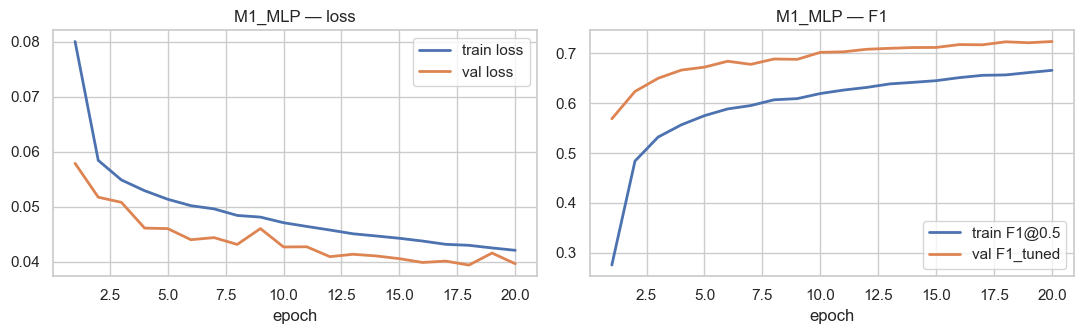

[M1_MLP] best val_F1_tuned=0.723, final (tr@0.5 − va_tuned)=-0.058 -> переобучение не видно



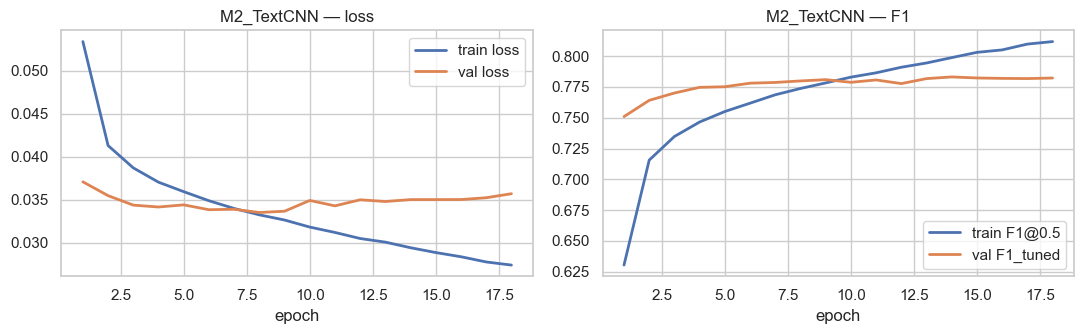

[M2_TextCNN] best val_F1_tuned=0.783, final (tr@0.5 − va_tuned)=+0.030 -> переобучение не видно



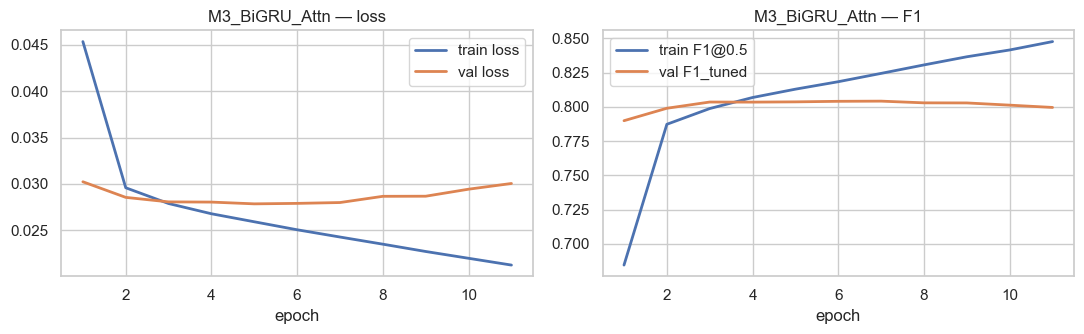

[M3_BiGRU_Attn] best val_F1_tuned=0.804, final (tr@0.5 − va_tuned)=+0.048 -> переобучение не видно



In [ ]:
def plot_history(h, name):
    ep = np.arange(1, len(h["train_loss"]) + 1)
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(ep, h["train_loss"], label="train loss", lw=2)
    ax[0].plot(ep, h["val_loss"],   label="val loss",   lw=2)
    ax[0].set_title(f"{name} — loss"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(ep, h["train_f1_thr05"], label="train F1@0.5", lw=2)
    ax[1].plot(ep, h["val_f1_tuned"],   label="val F1_tuned", lw=2)
    ax[1].set_title(f"{name} — F1"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

def overfit_report(h, name):
    last_gap = h["train_f1_thr05"][-1] - h["val_f1_tuned"][-1]
    best_val = max(h["val_f1_tuned"])
    print(f"[{name}] best val_F1_tuned={best_val:.3f}, "
          f"final (tr@0.5 − va_tuned)={last_gap:+.3f} -> ", end="")
    if last_gap > 0.15:   print("признаки переобучения")
    elif last_gap > 0.05: print("лёгкая переподгонка")
    else:                 print("переобучение не видно")

for n, h in [("M1_MLP", hist_m1), ("M2_TextCNN", hist_m2), ("M3_BiGRU_Attn", hist_m3)]:
    plot_history(h, n); overfit_report(h, n); print()

По графикам loss и F1 видно, что все три нейросетевые модели обучаются устойчиво: train loss снижается, а validation F1 достигает стабильного уровня без резких провалов. Это означает, что модели действительно извлекают полезный сигнал из текстовых признаков, а не дают случайный результат.

Для **M1_MLP** лучшая validation-метрика составила `val_F1_tuned = 0.723`. Train loss и val loss постепенно уменьшаются, а validation F1 растёт почти до конца обучения. Разрыв между train F1@0.5 и validation F1 с подобранным threshold в конце отрицательный: `-0.058`, поэтому признаков переобучения по этой модели не наблюдается. При этом качество MLP ниже, чем у более сложных архитектур, что ожидаемо: усреднённые признаки хуже передают порядок слов и локальные текстовые паттерны.

Для **M2_TextCNN** лучшая validation-метрика составила `val_F1_tuned = 0.783`. Модель заметно превосходит MLP, что показывает пользу сверточной архитектуры для выделения локальных n-граммных признаков в медицинских текстах. Train loss продолжает снижаться, а validation loss после первых эпох выходит на плато и слегка колеблется. Финальный разрыв `train F1@0.5 − val F1_tuned = +0.030` небольшой, поэтому выраженного переобучения не видно, хотя после достижения плато дальнейшее обучение уже почти не улучшает validation-качество.

Для **M3_BiGRU_Attn** лучшая validation-метрика составила `val_F1_tuned = 0.804`, что является лучшим результатом среди трёх моделей. Validation F1 быстро растёт в первые эпохи, затем стабилизируется около максимального значения. Train loss продолжает снижаться, а validation loss после минимума немного возрастает, поэтому можно говорить о насыщении модели и слабых признаках начального переобучения. Однако финальный разрыв `+0.048` остаётся умеренным, поэтому сильного переобучения не наблюдается.

Важно, что на графиках сравниваются не полностью одинаковые величины: для train используется `F1@0.5`, а для validation — `F1_tuned` с подобранным глобальным threshold. Поэтому разрыв между кривыми используется только как ориентировочная диагностика, а основной вывод о качестве моделей делается по validation-метрике с одинаковой процедурой настройки threshold.

В целом лучшую динамику и максимальное validation-качество показывает **M3_BiGRU_Attn**. Поэтому именно BiGRU с attention является наиболее сильной нейросетевой архитектурой на данном этапе эксперимента.

---
## 16. Гиперпараметрический подбор

Предыдущие learning curves показывают, что для базовых MLP, TextCNN и BiGRU явного сильного переобучения не видно; у tuned BiGRU далее появляется только лёгкая переподгонка. Поэтому следующим шагом выполняется подбор гиперпараметров.

В работе используются три процедуры подбора.

### 16.1. Holdout-подбор для TF-IDF + LR

Полный `GridSearchCV` заменён на holdout-подбор по validation, потому что многометочная схема One-vs-Rest делает полный перебор дорогим: каждая конфигурация обучает отдельный бинарный классификатор для каждой метки.

Фактически перебираются параметры:

- `ngram_range`;
- `min_df`;
- `max_features`;
- `C` логистической регрессии.

Лучший вариант в текущем запуске:

```text
ngram_range = (1, 2)
min_df = 15
max_features = 20000
C = 2.0
threshold = 0.25
val_micro_f1_tuned = 0.7879
```

### 16.2. Optuna для TextCNN

Для TextCNN используется Optuna/TPE. Подбираются `n_filters`, `dropout`, `lr`, а также варьируется `batch_size`. Поиск выполняется в сокращённом режиме, после чего лучшая конфигурация обучается отдельно как `M2_TextCNN_tuned`.

Лучшие параметры TextCNN в текущем запуске:

```text
n_filters = 96
dropout ≈ 0.4395
lr ≈ 0.000431
batch_size = 128
```

Итог после retrain: `M2_TextCNN_tuned` получил `val_micro_f1_tuned = 0.7886`.

### 16.3. Optuna для BiGRU + Attention

BiGRU также подбирается через Optuna.

Лучшие параметры:

```text
hidden = 192
dropout ≈ 0.2027
lr ≈ 0.000877
batch_size = 64
```

После retrain `M3_BiGRU_Attn_tuned` получил `val_micro_f1_tuned = 0.8074`, threshold `0.36` и стал лучшей моделью по validation.


In [ ]:
from sklearn.pipeline import Pipeline

train_texts = df_train["text"].fillna("").astype(str).tolist()
val_texts   = df_val["text"].fillna("").astype(str).tolist()

# Урезанное пространство поиска, подбираем минимум 3 гиперпараметра:
# ngram_range, min_df, max_features, C.
tfidf_param_list = [
    {"ngram_range": (1, 1), "min_df": 5,  "max_features": 20_000},
    {"ngram_range": (1, 1), "min_df": 10, "max_features": 30_000},
    {"ngram_range": (1, 1), "min_df": 15, "max_features": 40_000},

    # Биграммы оставляем, но только в более строгом режиме.
    {"ngram_range": (1, 2), "min_df": 10, "max_features": 15_000},
    {"ngram_range": (1, 2), "min_df": 15, "max_features": 20_000},
]

C_list = [0.5, 1.0, 2.0]

b1_tuning_rows = []
best_score = -1.0
best_pack = None

t0_all = time.time()

for tfidf_params in tfidf_param_list:
    print("\nTF-IDF params:", tfidf_params)

    gc.collect()

    tfidf = TfidfVectorizer(
        lowercase=True,
        max_df=0.90,
        sublinear_tf=True,
        dtype=np.float32,
        **tfidf_params
    )

    try:
        t0 = time.time()

        Xtr = tfidf.fit_transform(train_texts)
        Xva = tfidf.transform(val_texts)

        print(
            f"  Xtr={Xtr.shape}, Xva={Xva.shape}, "
            f"nnz={Xtr.nnz:,}, vectorize_time={time.time() - t0:.1f}s"
        )

    except MemoryError:
        print("  SKIPPED: MemoryError на TF-IDF vectorization")
        del tfidf
        gc.collect()
        continue

    for C in C_list:
        print(f"  LogisticRegression C={C}")

        t1 = time.time()

        clf = OneVsRestClassifier(
            LogisticRegression(
                max_iter=500,
                solver="liblinear",
                C=C,
                tol=1e-3,
                random_state=CONFIG["seed"]
            ),
            n_jobs=1
        )

        try:
            clf.fit(Xtr, Y_train_final)

            prob_va = clf.predict_proba(Xva).astype(np.float32)
            thr, f1_va = tune_threshold_micro(Y_val_final, prob_va)

            fit_time = time.time() - t1

            row = {
                "ngram_range": tfidf_params["ngram_range"],
                "min_df": tfidf_params["min_df"],
                "max_features": tfidf_params["max_features"],
                "C": C,
                "threshold": thr,
                "val_micro_f1_tuned": f1_va,
                "fit_time_s": fit_time,
            }

            b1_tuning_rows.append(row)

            print(
                f"    val_micro_f1_tuned={f1_va:.4f}, "
                f"thr={thr:.2f}, fit_time={fit_time:.1f}s"
            )

            if f1_va > best_score:
                best_score = f1_va
                best_pack = {
                    "tfidf": tfidf,
                    "clf": clf,
                    "prob_va": prob_va,
                    "threshold": thr,
                    "params": row,
                }

        except MemoryError:
            print("    SKIPPED: MemoryError на LogisticRegression")
            del clf
            gc.collect()
            continue

    del Xtr, Xva
    gc.collect()

if best_pack is None:
    raise RuntimeError(
        "Ни одна B1-конфигурация не обучилась. "
    )

df_b1_tuning = (
    pd.DataFrame(b1_tuning_rows)
    .sort_values("val_micro_f1_tuned", ascending=False)
    .reset_index(drop=True)
)

print("\n=== B1 tuning results ===")
display(df_b1_tuning)

print("\nBest B1 params:")
print(best_pack["params"])
print(f"Total tuning time: {(time.time() - t0_all) / 60:.1f} min")

best_tfidf_b1t = best_pack["tfidf"]
best_clf_b1t = best_pack["clf"]
prob_va_b1t = best_pack["prob_va"]
thr_b1t = best_pack["threshold"]

res_b1t = eval_multilabel(
    Y_val_final,
    (prob_va_b1t >= thr_b1t).astype(np.int8),
    prob_va_b1t,
    name="B1_TFIDF_LR_tuned"
)

res_b1t["val_micro_f1_tuned"] = float(best_pack["params"]["val_micro_f1_tuned"])
res_b1t["threshold"] = float(thr_b1t)
res_b1t["train_time_s"] = float(best_pack["params"]["fit_time_s"])
res_b1t["best_params"] = str(best_pack["params"])

RESULTS.append(res_b1t)

print(f"[B1-tuned] val_micro_f1_tuned = {res_b1t['val_micro_f1_tuned']:.4f}")
print(f"[B1-tuned] threshold = {thr_b1t:.2f}")


TF-IDF params: {'ngram_range': (1, 1), 'min_df': 5, 'max_features': 20000}
  Xtr=(143283, 20000), Xva=(30388, 20000), nnz=17,514,899, vectorize_time=34.5s
  LogisticRegression C=0.5
    val_micro_f1_tuned=0.7692, thr=0.22, fit_time=94.8s
  LogisticRegression C=1.0
    val_micro_f1_tuned=0.7766, thr=0.25, fit_time=102.1s
  LogisticRegression C=2.0
    val_micro_f1_tuned=0.7808, thr=0.27, fit_time=114.3s

TF-IDF params: {'ngram_range': (1, 1), 'min_df': 10, 'max_features': 30000}
  Xtr=(143283, 30000), Xva=(30388, 30000), nnz=17,700,208, vectorize_time=36.5s
  LogisticRegression C=0.5
    val_micro_f1_tuned=0.7687, thr=0.22, fit_time=100.5s
  LogisticRegression C=1.0
    val_micro_f1_tuned=0.7760, thr=0.25, fit_time=106.8s
  LogisticRegression C=2.0
    val_micro_f1_tuned=0.7805, thr=0.26, fit_time=119.3s

TF-IDF params: {'ngram_range': (1, 1), 'min_df': 15, 'max_features': 40000}
  Xtr=(143283, 25189), Xva=(30388, 25189), nnz=17,642,748, vectorize_time=33.7s
  LogisticRegression C=0.5


,ngram_range,min_df,max_features,C,threshold,val_micro_f1_tuned,fit_time_s
0,"(1, 2)",15,20000,2.0,0.25,0.787914,180.862456
1,"(1, 2)",10,15000,2.0,0.28,0.787172,169.684465
2,"(1, 2)",15,20000,1.0,0.24,0.783660,161.288991
3,"(1, 2)",10,15000,1.0,0.25,0.783202,149.548025
4,"(1, 1)",5,20000,2.0,0.27,0.780799,114.283959
5,"(1, 1)",15,40000,2.0,0.25,0.780751,117.822912
6,"(1, 1)",10,30000,2.0,0.26,0.780480,119.281587
7,"(1, 2)",15,20000,0.5,0.20,0.776698,148.063776
8,"(1, 1)",5,20000,1.0,0.25,0.776597,102.144412
9,"(1, 1)",15,40000,1.0,0.25,0.776382,105.034280



Best B1 params:
{'ngram_range': (1, 2), 'min_df': 15, 'max_features': 20000, 'C': 2.0, 'threshold': 0.24999999999999994, 'val_micro_f1_tuned': 0.7879141657043514, 'fit_time_s': 180.86245608329773}
Total tuning time: 105.8 min
[B1-tuned] val_micro_f1_tuned = 0.7879
[B1-tuned] threshold = 0.25


In [ ]:
import optuna
from optuna.samplers import TPESampler

def objective_m2(trial):
    n_filters   = trial.suggest_categorical("n_filters", [64, 96, 128])
    dropout     = trial.suggest_float("dropout", 0.2, 0.6)
    lr          = trial.suggest_float("lr", 3e-4, 3e-3, log=True)
    bs          = trial.suggest_categorical("batch_size", [32, 64, 128])

    cfg_t = dict(CONFIG)
    cfg_t.update({"max_epochs": 8, "patience": 2, "batch_size": bs, "lr": lr})
    _, hist, res = train_model(TextCNN, f"M2_trial_{trial.number}",
                                cfg=cfg_t, evaluate_test=False,
                                n_filters=n_filters, dropout=dropout,
                                kernel_sizes=(3, 5, 7))
    return res["val_micro_f1_tuned"]

study = optuna.create_study(direction="maximize",
                            sampler=TPESampler(seed=CONFIG["seed"]))
study.optimize(objective_m2, n_trials=15, show_progress_bar=True)
print("Best params (M2):", study.best_params)
print(f"Best val_micro_f1_tuned: {study.best_value:.4f}")

A:\conda-envs\torch_env\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[I 2026-04-28 01:18:47,262] A new study created in memory with name: no-name-78b65a71-44df-437b-9ea3-e8c4416ce3a7
  0%|                                                                                           | 0/15 [00:00<?, ?it/s]

[M2_trial_0] ep 01  tr_loss=0.0687  va_loss=0.0389  tr_F1@0.5=0.514  va_F1_tuned=0.737 (thr=0.23)
[M2_trial_0] ep 02  tr_loss=0.0422  va_loss=0.0354  tr_F1@0.5=0.695  va_F1_tuned=0.757 (thr=0.27)
[M2_trial_0] ep 03  tr_loss=0.0388  va_loss=0.0340  tr_F1@0.5=0.722  va_F1_tuned=0.768 (thr=0.23)
[M2_trial_0] ep 04  tr_loss=0.0370  va_loss=0.0333  tr_F1@0.5=0.734  va_F1_tuned=0.771 (thr=0.26)
[M2_trial_0] ep 05  tr_loss=0.0357  va_loss=0.0328  tr_F1@0.5=0.743  va_F1_tuned=0.775 (thr=0.26)
[M2_trial_0] ep 06  tr_loss=0.0347  va_loss=0.0326  tr_F1@0.5=0.751  va_F1_tuned=0.778 (thr=0.25)
[M2_trial_0] ep 07  tr_loss=0.0338  va_loss=0.0322  tr_F1@0.5=0.757  va_F1_tuned=0.780 (thr=0.25)
[M2_trial_0] ep 08  tr_loss=0.0330  va_loss=0.0319  tr_F1@0.5=0.763  va_F1_tuned=0.782 (thr=0.26)


Best trial: 0. Best value: 0.781725:   7%|███                                          | 1/15 [03:46<52:52, 226.64s/it]

[I 2026-04-28 01:22:34,138] Trial 0 finished with value: 0.7817253661484653 and parameters: {'n_filters': 96, 'dropout': 0.4394633936788146, 'lr': 0.0004296748115469076, 'batch_size': 128}. Best is trial 0 with value: 0.7817253661484653.
[M2_trial_1] ep 01  tr_loss=0.0702  va_loss=0.0450  tr_F1@0.5=0.565  va_F1_tuned=0.723 (thr=0.19)
[M2_trial_1] ep 02  tr_loss=0.0565  va_loss=0.0428  tr_F1@0.5=0.648  va_F1_tuned=0.736 (thr=0.26)
[M2_trial_1] ep 03  tr_loss=0.0532  va_loss=0.0416  tr_F1@0.5=0.661  va_F1_tuned=0.750 (thr=0.21)
[M2_trial_1] ep 04  tr_loss=0.0517  va_loss=0.0414  tr_F1@0.5=0.665  va_F1_tuned=0.753 (thr=0.18)
[M2_trial_1] ep 05  tr_loss=0.0509  va_loss=0.0419  tr_F1@0.5=0.669  va_F1_tuned=0.752 (thr=0.18)
[M2_trial_1] ep 06  tr_loss=0.0507  va_loss=0.0426  tr_F1@0.5=0.671  va_F1_tuned=0.750 (thr=0.17)
[M2_trial_1] early stopping @ ep 6


Best trial: 0. Best value: 0.781725:  13%|█████▋                                     | 2/15 [10:14<1:09:36, 321.26s/it]

[I 2026-04-28 01:29:01,629] Trial 1 finished with value: 0.7530513203654973 and parameters: {'n_filters': 96, 'dropout': 0.5879639408647976, 'lr': 0.0020396887264773375, 'batch_size': 32}. Best is trial 0 with value: 0.7817253661484653.
[M2_trial_2] ep 01  tr_loss=0.0529  va_loss=0.0356  tr_F1@0.5=0.634  va_F1_tuned=0.755 (thr=0.26)
[M2_trial_2] ep 02  tr_loss=0.0386  va_loss=0.0342  tr_F1@0.5=0.727  va_F1_tuned=0.766 (thr=0.28)
[M2_trial_2] ep 03  tr_loss=0.0364  va_loss=0.0339  tr_F1@0.5=0.745  va_F1_tuned=0.771 (thr=0.31)
[M2_trial_2] ep 04  tr_loss=0.0348  va_loss=0.0334  tr_F1@0.5=0.757  va_F1_tuned=0.777 (thr=0.27)
[M2_trial_2] ep 05  tr_loss=0.0335  va_loss=0.0334  tr_F1@0.5=0.766  va_F1_tuned=0.778 (thr=0.26)
[M2_trial_2] ep 06  tr_loss=0.0326  va_loss=0.0339  tr_F1@0.5=0.773  va_F1_tuned=0.778 (thr=0.23)
[M2_trial_2] ep 07  tr_loss=0.0316  va_loss=0.0331  tr_F1@0.5=0.779  va_F1_tuned=0.780 (thr=0.31)
[M2_trial_2] ep 08  tr_loss=0.0307  va_loss=0.0333  tr_F1@0.5=0.786  va_F1_tu

... (22 outputs left out)

Best trial: 13. Best value: 0.781989:  93%|██████████████████████████████████████▎  | 14/15 [1:09:45<04:13, 253.33s/it]

[I 2026-04-28 02:28:33,176] Trial 13 finished with value: 0.7819885223481895 and parameters: {'n_filters': 96, 'dropout': 0.4394654526757008, 'lr': 0.00043134285222518005, 'batch_size': 128}. Best is trial 13 with value: 0.7819885223481895.
[M2_trial_14] ep 01  tr_loss=0.0643  va_loss=0.0376  tr_F1@0.5=0.545  va_F1_tuned=0.742 (thr=0.25)
[M2_trial_14] ep 02  tr_loss=0.0407  va_loss=0.0344  tr_F1@0.5=0.705  va_F1_tuned=0.760 (thr=0.29)
[M2_trial_14] ep 03  tr_loss=0.0376  va_loss=0.0335  tr_F1@0.5=0.729  va_F1_tuned=0.769 (thr=0.25)
[M2_trial_14] ep 04  tr_loss=0.0358  va_loss=0.0327  tr_F1@0.5=0.741  va_F1_tuned=0.773 (thr=0.24)
[M2_trial_14] ep 05  tr_loss=0.0346  va_loss=0.0324  tr_F1@0.5=0.750  va_F1_tuned=0.776 (thr=0.26)
[M2_trial_14] ep 06  tr_loss=0.0335  va_loss=0.0320  tr_F1@0.5=0.758  va_F1_tuned=0.779 (thr=0.27)
[M2_trial_14] ep 07  tr_loss=0.0326  va_loss=0.0318  tr_F1@0.5=0.765  va_F1_tuned=0.781 (thr=0.30)
[M2_trial_14] ep 08  tr_loss=0.0319  va_loss=0.0317  tr_F1@0.5=0.7

Best trial: 13. Best value: 0.781989: 100%|█████████████████████████████████████████| 15/15 [1:13:22<00:00, 293.52s/it]

[I 2026-04-28 02:32:10,354] Trial 14 finished with value: 0.7809464362345414 and parameters: {'n_filters': 128, 'dropout': 0.4489651478574052, 'lr': 0.0004192127268650983, 'batch_size': 128}. Best is trial 13 with value: 0.7819885223481895.
Best params (M2): {'n_filters': 96, 'dropout': 0.4394654526757008, 'lr': 0.00043134285222518005, 'batch_size': 128}
Best val_micro_f1_tuned: 0.7820


[M2_TextCNN_tuned] ep 01  tr_loss=0.0662  va_loss=0.0383  tr_F1@0.5=0.531  va_F1_tuned=0.739 (thr=0.24)
[M2_TextCNN_tuned] ep 02  tr_loss=0.0419  va_loss=0.0351  tr_F1@0.5=0.697  va_F1_tuned=0.758 (thr=0.29)
[M2_TextCNN_tuned] ep 03  tr_loss=0.0387  va_loss=0.0339  tr_F1@0.5=0.722  va_F1_tuned=0.768 (thr=0.23)
[M2_TextCNN_tuned] ep 04  tr_loss=0.0370  va_loss=0.0331  tr_F1@0.5=0.733  va_F1_tuned=0.772 (thr=0.26)
[M2_TextCNN_tuned] ep 05  tr_loss=0.0357  va_loss=0.0328  tr_F1@0.5=0.743  va_F1_tuned=0.776 (thr=0.25)
[M2_TextCNN_tuned] ep 06  tr_loss=0.0347  va_loss=0.0324  tr_F1@0.5=0.751  va_F1_tuned=0.778 (thr=0.24)
[M2_TextCNN_tuned] ep 07  tr_loss=0.0338  va_loss=0.0321  tr_F1@0.5=0.758  va_F1_tuned=0.779 (thr=0.27)
[M2_TextCNN_tuned] ep 08  tr_loss=0.0331  va_loss=0.0320  tr_F1@0.5=0.763  va_F1_tuned=0.781 (thr=0.28)
[M2_TextCNN_tuned] ep 09  tr_loss=0.0324  va_loss=0.0317  tr_F1@0.5=0.768  va_F1_tuned=0.783 (thr=0.30)
[M2_TextCNN_tuned] ep 10  tr_loss=0.0318  va_loss=0.0320  tr_F1@

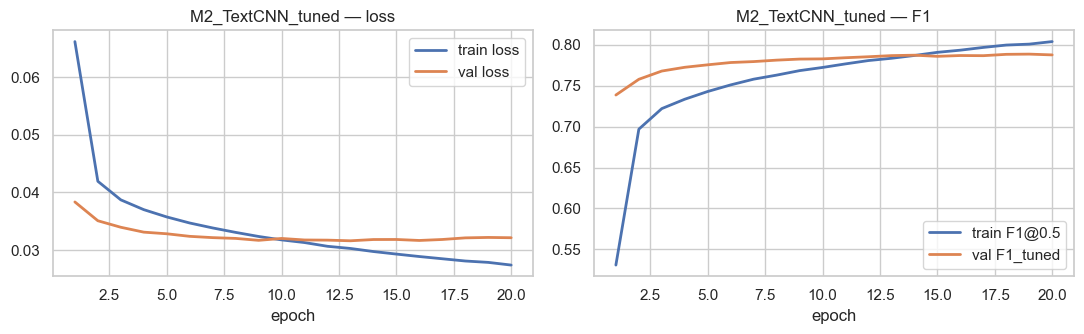

[M2_TextCNN_tuned] best val_F1_tuned=0.789, final (tr@0.5 − va_tuned)=+0.016 -> переобучение не видно
[M2-tuned] val_micro_f1_tuned = 0.7886


In [ ]:
# Финальный прогон M2 с лучшими гиперпараметрами на полном числе эпох
bp = study.best_params
cfg_best = dict(CONFIG)
cfg_best.update({"batch_size": bp["batch_size"], "lr": bp["lr"]})

model_m2t, hist_m2t, res_m2t = train_model(
    TextCNN, "M2_TextCNN_tuned",
    cfg=cfg_best, evaluate_test=False,
    n_filters=bp["n_filters"], dropout=bp["dropout"],
    kernel_sizes=(3, 5, 7),
)
RESULTS.append(res_m2t)
plot_history(hist_m2t, "M2_TextCNN_tuned")
overfit_report(hist_m2t, "M2_TextCNN_tuned")
print(f"[M2-tuned] val_micro_f1_tuned = {res_m2t['val_micro_f1_tuned']:.4f}")

После подбора гиперпараметров модель **M2_TextCNN_tuned** обучается устойчиво. Train loss последовательно снижается с `0.0662` до `0.0274`, а validation loss быстро уменьшается в первые эпохи и затем стабилизируется около `0.0316–0.0322`. Это показывает, что модель быстро находит полезные локальные текстовые признаки, после чего дальнейшее обучение даёт уже небольшой прирост.

Validation F1 также растёт постепенно: с `0.739` на первой эпохе до максимального значения `0.789` на 19-й эпохе. После 9–13-й эпохи рост становится очень медленным, то есть модель выходит на плато качества. Финальное значение `val_F1_tuned = 0.788` практически совпадает с максимумом, поэтому выбранная длительность обучения не приводит к заметной деградации качества.

Разрыв между `train F1@0.5 = 0.804` и `val F1_tuned = 0.788` в конце обучения составляет около `0.016`. Он небольшой, поэтому выраженного переобучения не наблюдается. При этом validation loss после середины обучения немного колеблется и слегка растёт, что можно интерпретировать как насыщение модели: она продолжает лучше подстраиваться под train, но validation-качество уже почти не улучшается.

В целом **M2_TextCNN_tuned** показывает стабильное обучение и даёт лучший результат, чем исходная TextCNN до подбора гиперпараметров: максимальное validation-качество увеличилось примерно с `0.783` до `0.789`. Прирост небольшой, но он подтверждает, что Optuna-подбор улучшил конфигурацию модели без явных признаков переобучения.

In [ ]:
# Optuna-подбор гиперпараметров для M3: BiGRU + Attention
# Логика такая же, как для M2:
# 1) Optuna ищет гиперпараметры в сокращённом режиме;
# 2) лучшая конфигурация потом обучается заново в полном режиме;
# 3) итоговая модель добавляется в RESULTS как M3_BiGRU_Attn_tuned.

def objective_m3(trial):
    hidden = trial.suggest_categorical("hidden", [64, 128, 192])
    dropout = trial.suggest_float("dropout", 0.2, 0.6)
    lr = trial.suggest_float("lr", 3e-4, 3e-3, log=True)
    bs = trial.suggest_categorical("batch_size", [32, 64, 128])

    cfg_t = dict(CONFIG)
    cfg_t.update({
        "max_epochs": 8,      # сокращённый режим для ускоренного поиска
        "patience": 2,
        "batch_size": bs,
        "lr": lr,
    })

    model_tmp, hist_tmp, res_tmp = train_model(
        BiGRUAttn,
        f"M3_trial_{trial.number}",
        cfg=cfg_t,
        evaluate_test=False,
        hidden=hidden,
        dropout=dropout,
    )

    score = res_tmp["val_micro_f1_tuned"]

    # Чистим память между trial'ами, особенно важно для GRU на GPU
    del model_tmp, hist_tmp, res_tmp
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return score


study_m3 = optuna.create_study(
    direction="maximize",
    sampler=TPESampler(seed=CONFIG["seed"])
)

study_m3.optimize(objective_m3, n_trials=15, show_progress_bar=True)

print("Best params (M3):", study_m3.best_params)
print(f"Best val_micro_f1_tuned during search: {study_m3.best_value:.4f}")

[I 2026-04-28 03:32:38,736] A new study created in memory with name: no-name-61e63ede-c510-4159-a0a1-b609be789c19
  0%|                                                                                           | 0/15 [00:00<?, ?it/s]

[M3_trial_0] ep 01  tr_loss=0.0740  va_loss=0.0368  tr_F1@0.5=0.480  va_F1_tuned=0.759 (thr=0.26)
[M3_trial_0] ep 02  tr_loss=0.0348  va_loss=0.0317  tr_F1@0.5=0.749  va_F1_tuned=0.784 (thr=0.27)
[M3_trial_0] ep 03  tr_loss=0.0311  va_loss=0.0300  tr_F1@0.5=0.778  va_F1_tuned=0.794 (thr=0.26)
[M3_trial_0] ep 04  tr_loss=0.0294  va_loss=0.0291  tr_F1@0.5=0.789  va_F1_tuned=0.799 (thr=0.28)
[M3_trial_0] ep 05  tr_loss=0.0281  va_loss=0.0285  tr_F1@0.5=0.798  va_F1_tuned=0.801 (thr=0.31)
[M3_trial_0] ep 06  tr_loss=0.0272  va_loss=0.0283  tr_F1@0.5=0.804  va_F1_tuned=0.802 (thr=0.31)
[M3_trial_0] ep 07  tr_loss=0.0265  va_loss=0.0282  tr_F1@0.5=0.810  va_F1_tuned=0.804 (thr=0.32)
[M3_trial_0] ep 08  tr_loss=0.0258  va_loss=0.0284  tr_F1@0.5=0.815  va_F1_tuned=0.804 (thr=0.30)


Best trial: 0. Best value: 0.803801:   7%|██▊                                       | 1/15 [22:23<5:13:29, 1343.55s/it]

[I 2026-04-28 03:55:02,260] Trial 0 finished with value: 0.8038010638847286 and parameters: {'hidden': 128, 'dropout': 0.4394633936788146, 'lr': 0.0004296748115469076, 'batch_size': 128}. Best is trial 0 with value: 0.8038010638847286.
[M3_trial_1] ep 01  tr_loss=0.0421  va_loss=0.0320  tr_F1@0.5=0.709  va_F1_tuned=0.784 (thr=0.23)
[M3_trial_1] ep 02  tr_loss=0.0346  va_loss=0.0309  tr_F1@0.5=0.760  va_F1_tuned=0.790 (thr=0.24)
[M3_trial_1] ep 03  tr_loss=0.0332  va_loss=0.0303  tr_F1@0.5=0.770  va_F1_tuned=0.792 (thr=0.29)
[M3_trial_1] ep 04  tr_loss=0.0323  va_loss=0.0302  tr_F1@0.5=0.776  va_F1_tuned=0.796 (thr=0.27)
[M3_trial_1] ep 05  tr_loss=0.0314  va_loss=0.0304  tr_F1@0.5=0.783  va_F1_tuned=0.793 (thr=0.26)
[M3_trial_1] ep 06  tr_loss=0.0305  va_loss=0.0304  tr_F1@0.5=0.788  va_F1_tuned=0.793 (thr=0.25)
[M3_trial_1] early stopping @ ep 6


Best trial: 0. Best value: 0.803801:  13%|█████▎                                  | 2/15 [1:07:06<7:41:47, 2131.31s/it]

[I 2026-04-28 04:39:44,988] Trial 1 finished with value: 0.7964697825272326 and parameters: {'hidden': 128, 'dropout': 0.5879639408647976, 'lr': 0.0020396887264773375, 'batch_size': 32}. Best is trial 0 with value: 0.8038010638847286.
[M3_trial_2] ep 01  tr_loss=0.0512  va_loss=0.0311  tr_F1@0.5=0.644  va_F1_tuned=0.786 (thr=0.30)
[M3_trial_2] ep 02  tr_loss=0.0294  va_loss=0.0290  tr_F1@0.5=0.787  va_F1_tuned=0.796 (thr=0.31)
[M3_trial_2] ep 03  tr_loss=0.0273  va_loss=0.0280  tr_F1@0.5=0.801  va_F1_tuned=0.803 (thr=0.35)
[M3_trial_2] ep 04  tr_loss=0.0261  va_loss=0.0278  tr_F1@0.5=0.809  va_F1_tuned=0.804 (thr=0.31)
[M3_trial_2] ep 05  tr_loss=0.0252  va_loss=0.0276  tr_F1@0.5=0.816  va_F1_tuned=0.806 (thr=0.31)
[M3_trial_2] ep 06  tr_loss=0.0243  va_loss=0.0277  tr_F1@0.5=0.822  va_F1_tuned=0.806 (thr=0.37)
[M3_trial_2] ep 07  tr_loss=0.0235  va_loss=0.0280  tr_F1@0.5=0.829  va_F1_tuned=0.806 (thr=0.36)
[M3_trial_2] early stopping @ ep 7


... (22 outputs left out)

Best trial: 12. Best value: 0.808888:  93%|█████████████████████████████████████▎  | 14/15 [7:48:35<32:50, 1970.03s/it]

[I 2026-04-28 11:21:13,922] Trial 13 finished with value: 0.8042017021494109 and parameters: {'hidden': 64, 'dropout': 0.21113902806920012, 'lr': 0.0009920361650101977, 'batch_size': 64}. Best is trial 12 with value: 0.8088879643233263.
[M3_trial_14] ep 01  tr_loss=0.0377  va_loss=0.0291  tr_F1@0.5=0.734  va_F1_tuned=0.795 (thr=0.34)
[M3_trial_14] ep 02  tr_loss=0.0275  va_loss=0.0280  tr_F1@0.5=0.799  va_F1_tuned=0.800 (thr=0.34)
[M3_trial_14] ep 03  tr_loss=0.0261  va_loss=0.0280  tr_F1@0.5=0.808  va_F1_tuned=0.802 (thr=0.35)
[M3_trial_14] ep 04  tr_loss=0.0250  va_loss=0.0279  tr_F1@0.5=0.816  va_F1_tuned=0.804 (thr=0.32)
[M3_trial_14] ep 05  tr_loss=0.0240  va_loss=0.0281  tr_F1@0.5=0.824  va_F1_tuned=0.803 (thr=0.35)
[M3_trial_14] ep 06  tr_loss=0.0232  va_loss=0.0281  tr_F1@0.5=0.829  va_F1_tuned=0.807 (thr=0.37)
[M3_trial_14] ep 07  tr_loss=0.0223  va_loss=0.0287  tr_F1@0.5=0.836  va_F1_tuned=0.804 (thr=0.33)
[M3_trial_14] ep 08  tr_loss=0.0214  va_loss=0.0294  tr_F1@0.5=0.844  

Best trial: 12. Best value: 0.808888: 100%|████████████████████████████████████████| 15/15 [8:22:25<00:00, 2009.69s/it]

[I 2026-04-28 11:55:04,047] Trial 14 finished with value: 0.8069192923688894 and parameters: {'hidden': 192, 'dropout': 0.2723903488613836, 'lr': 0.0014253886604103398, 'batch_size': 64}. Best is trial 12 with value: 0.8088879643233263.
Best params (M3): {'hidden': 192, 'dropout': 0.202711572872698, 'lr': 0.0008769314002973458, 'batch_size': 64}
Best val_micro_f1_tuned during search: 0.8089


[M3_BiGRU_Attn_tuned] ep 01  tr_loss=0.0400  va_loss=0.0290  tr_F1@0.5=0.717  va_F1_tuned=0.795 (thr=0.36)
[M3_BiGRU_Attn_tuned] ep 02  tr_loss=0.0267  va_loss=0.0277  tr_F1@0.5=0.802  va_F1_tuned=0.802 (thr=0.40)
[M3_BiGRU_Attn_tuned] ep 03  tr_loss=0.0250  va_loss=0.0273  tr_F1@0.5=0.814  va_F1_tuned=0.807 (thr=0.36)
[M3_BiGRU_Attn_tuned] ep 04  tr_loss=0.0237  va_loss=0.0272  tr_F1@0.5=0.823  va_F1_tuned=0.807 (thr=0.33)
[M3_BiGRU_Attn_tuned] ep 05  tr_loss=0.0226  va_loss=0.0273  tr_F1@0.5=0.833  va_F1_tuned=0.807 (thr=0.36)
[M3_BiGRU_Attn_tuned] ep 06  tr_loss=0.0215  va_loss=0.0278  tr_F1@0.5=0.840  va_F1_tuned=0.807 (thr=0.37)
[M3_BiGRU_Attn_tuned] ep 07  tr_loss=0.0204  va_loss=0.0283  tr_F1@0.5=0.849  va_F1_tuned=0.805 (thr=0.39)
[M3_BiGRU_Attn_tuned] ep 08  tr_loss=0.0194  va_loss=0.0292  tr_F1@0.5=0.856  va_F1_tuned=0.805 (thr=0.33)
[M3_BiGRU_Attn_tuned] ep 09  tr_loss=0.0184  va_loss=0.0295  tr_F1@0.5=0.864  va_F1_tuned=0.804 (thr=0.35)
[M3_BiGRU_Attn_tuned] early stopping 

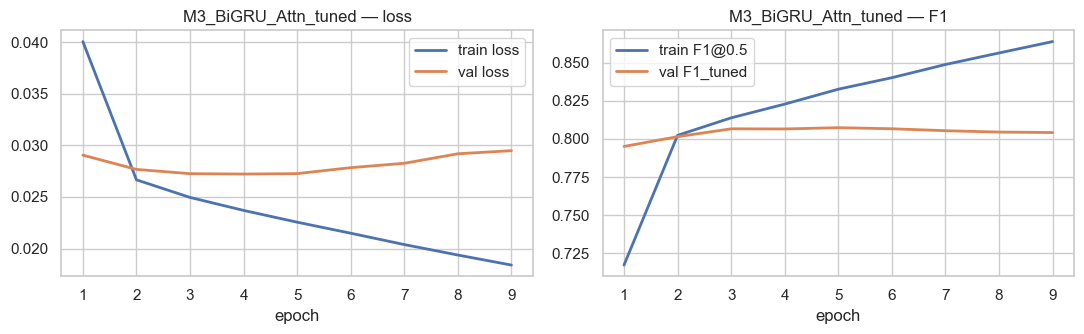

[M3_BiGRU_Attn_tuned] best val_F1_tuned=0.807, final (tr@0.5 − va_tuned)=+0.060 -> лёгкая переподгонка
[M3-tuned] val_micro_f1_tuned = 0.8074
[M3-tuned] threshold = 0.36
[M3-tuned] best params = {'hidden': 192, 'dropout': 0.202711572872698, 'lr': 0.0008769314002973458, 'batch_size': 64}


In [ ]:
# Финальный прогон M3 с лучшими гиперпараметрами на полном числе эпох
bp_m3 = study_m3.best_params

cfg_best_m3 = dict(CONFIG)
cfg_best_m3.update({
    "batch_size": bp_m3["batch_size"],
    "lr": bp_m3["lr"],
})

model_m3t, hist_m3t, res_m3t = train_model(
    BiGRUAttn,
    "M3_BiGRU_Attn_tuned",
    cfg=cfg_best_m3,
    evaluate_test=False,
    hidden=bp_m3["hidden"],
    dropout=bp_m3["dropout"],
)

res_m3t["best_params"] = str(bp_m3)
res_m3t["optuna_search_val_micro_f1"] = float(study_m3.best_value)

RESULTS.append(res_m3t)

plot_history(hist_m3t, "M3_BiGRU_Attn_tuned")
overfit_report(hist_m3t, "M3_BiGRU_Attn_tuned")

print(f"[M3-tuned] val_micro_f1_tuned = {res_m3t['val_micro_f1_tuned']:.4f}")
print(f"[M3-tuned] threshold = {res_m3t['threshold']:.2f}")
print(f"[M3-tuned] best params = {bp_m3}")

После подбора гиперпараметров модель **M3_BiGRU_Attn_tuned** показала лучший validation-результат среди нейросетевых моделей. Максимальное значение `val_F1_tuned` составило `0.8074` при глобальном threshold `0.36`.

Однако лучший trial Optuna достиг val_micro_f1_tuned = 0.8089, поэтому прирост относительно базовой BiGRU следует считать небольшим и чувствительным к стохастике обучения.

На графике loss видно, что train loss устойчиво снижается с `0.0400` до `0.0184`, то есть модель продолжает всё лучше подстраиваться под обучающую выборку. Validation loss сначала уменьшается до минимума около `0.0272` на 4-й эпохе, но затем начинает постепенно расти до `0.0295`. Это указывает на начало переподгонки после первых эпох обучения.

Validation F1 быстро достигает высокого уровня: уже на 3–6-й эпохах значение `val_F1_tuned` находится около `0.807`. После этого улучшения почти нет, а к 9-й эпохе validation F1 немного снижается до `0.804`. При этом train F1@0.5 продолжает расти с `0.717` до `0.864`. Финальный разрыв между `train F1@0.5` и `val F1_tuned` составляет около `+0.060`, поэтому можно говорить о **лёгкой переподгонке**, но не о критическом переобучении.

Early stopping сработал на 9-й эпохе, дальнейшее обучение уже не улучшало validation F1 и сопровождалось ростом validation loss. Поэтому для итогового сравнения следует использовать лучший checkpoint.

В целом tuned BiGRU с attention является наиболее сильной моделью на validation-выборке. По сравнению с исходной BiGRU качество выросло незначительно, примерно с `0.804` до `0.807`, но этот результат всё равно подтверждает, что после Optuna-подбора BiGRU остаётся лучшей архитектурой в эксперименте.

### 16.4. Дополнительный эксперимент: `BCEWithLogitsLoss + pos_weight`

Для каждой метки `pos_weight` задаёт повышенный вес положительных примеров:

$$
\mathrm{pos\_weight}_j =
\frac{N_{\mathrm{neg},j}}{N_{\mathrm{pos},j}}
$$

Идея состоит в том, чтобы компенсировать дисбаланс labels. Однако в multi-label задаче это часто повышает recall и одновременно снижает precision, поэтому итоговый micro-F1 может ухудшиться.

`M2_TextCNN_posw` получил `val_micro_f1_tuned = 0.7644`, что ниже обычного `M2_TextCNN` (`0.7831`) и tuned TextCNN (`0.7886`). Поэтому `pos_weight` рассматривается как абляция, а не как финальное решение.


In [ ]:
model_m2pw, hist_m2pw, res_m2pw = train_model(
    TextCNN, "M2_TextCNN_posw",
    cfg=cfg_best, evaluate_test=False, use_pos_weight=True,
    n_filters=bp["n_filters"], dropout=bp["dropout"],
    kernel_sizes=(3, 5, 7),
)
RESULTS.append(res_m2pw)
print(f"[M2-posw] val_micro_f1_tuned = {res_m2pw['val_micro_f1_tuned']:.4f} | "
      f"macro_f1 = {res_m2pw['macro_f1']:.4f}")


[M2_TextCNN_posw] ep 01  tr_loss=0.2679  va_loss=0.1489  tr_F1@0.5=0.466  va_F1_tuned=0.699 (thr=0.60)
[M2_TextCNN_posw] ep 02  tr_loss=0.1650  va_loss=0.1344  tr_F1@0.5=0.623  va_F1_tuned=0.717 (thr=0.60)
[M2_TextCNN_posw] ep 03  tr_loss=0.1499  va_loss=0.1270  tr_F1@0.5=0.651  va_F1_tuned=0.728 (thr=0.60)
[M2_TextCNN_posw] ep 04  tr_loss=0.1419  va_loss=0.1239  tr_F1@0.5=0.668  va_F1_tuned=0.738 (thr=0.60)
[M2_TextCNN_posw] ep 05  tr_loss=0.1356  va_loss=0.1225  tr_F1@0.5=0.678  va_F1_tuned=0.740 (thr=0.60)
[M2_TextCNN_posw] ep 06  tr_loss=0.1306  va_loss=0.1204  tr_F1@0.5=0.687  va_F1_tuned=0.740 (thr=0.60)
[M2_TextCNN_posw] ep 07  tr_loss=0.1267  va_loss=0.1200  tr_F1@0.5=0.695  va_F1_tuned=0.745 (thr=0.60)
[M2_TextCNN_posw] ep 08  tr_loss=0.1237  va_loss=0.1195  tr_F1@0.5=0.700  va_F1_tuned=0.746 (thr=0.60)
[M2_TextCNN_posw] ep 09  tr_loss=0.1201  va_loss=0.1190  tr_F1@0.5=0.706  va_F1_tuned=0.749 (thr=0.60)
[M2_TextCNN_posw] ep 10  tr_loss=0.1175  va_loss=0.1186  tr_F1@0.5=0.710 

---
## 17. Финальная оценка на test

Финальный выбор модели делается по `val_micro_f1_tuned`. test не участвовал в принятии решений, но часть test-прогнозов была предварительно рассчитана для бейзлайнов.

В этом разделе собирается единая таблица:

1. берутся все модели из `RESULTS`;
2. сортировка выполняется по `val_micro_f1_tuned`;
3. для каждой модели добавляются test-метрики;
4. лучшая по validation модель фиксируется для анализа ошибок.


In [ ]:
# Итоговая таблица val-метрик
df_val_results = (pd.DataFrame(RESULTS)
                    .sort_values("val_micro_f1_tuned", ascending=False)
                    .reset_index(drop=True))
print("Топ моделей по val_micro_f1_tuned:")
print(df_val_results[["model", "val_micro_f1_tuned", "threshold"]].round(4))

best_name = df_val_results.iloc[0]["model"]
best_thr  = df_val_results.iloc[0]["threshold"]
print(f"\n>>> Лучшая модель по val: {best_name} (val_F1_tuned = "
      f"{df_val_results.iloc[0]['val_micro_f1_tuned']:.4f})")


Топ моделей по val_micro_f1_tuned:
                  model  val_micro_f1_tuned  threshold
0   M3_BiGRU_Attn_tuned              0.8074       0.36
1         M3_BiGRU_Attn              0.8041       0.34
2      M2_TextCNN_tuned              0.7886       0.31
3     B1_TFIDF_LR_tuned              0.7879       0.25
4            M2_TextCNN              0.7831       0.25
5           B1_TFIDF_LR              0.7823       0.20
6       M2_TextCNN_posw              0.7644       0.60
7                M1_MLP              0.7235       0.27
8          B2_AvgW2V_LR              0.6894       0.27
9          B0b_MostFreq              0.1115        NaN
10             B0c_Top1              0.1115        NaN
11          B0a_AllZero              0.0000        NaN

>>> Лучшая модель по val: M3_BiGRU_Attn_tuned (val_F1_tuned = 0.8074)


In [ ]:
# Считаем test-метрики для всех моделей.
# Каждая модель имеет свои сохранённые prob_te / threshold; собираем единообразно.

def test_metrics_for(name):
    """Возвращает eval_multilabel(...) на test для конкретной модели по имени."""
    if name == "B0a_AllZero":
        pred = np.zeros_like(Y_test_final); prob = np.zeros_like(Y_test_final).astype(np.float32)
        return eval_multilabel(Y_test_final, pred, prob, name=name)
    if name == "B0b_MostFreq":
        pred = np.zeros_like(Y_test_final); pred[:, mf_idx] = 1
        prob = np.zeros_like(Y_test_final).astype(np.float32); prob[:, mf_idx] = 1.0
        return eval_multilabel(Y_test_final, pred, prob, name=name)
    if name.startswith("B0c_Top"):
        pred = np.zeros_like(Y_test_final); pred[:, topk_idx] = 1
        prob = np.zeros_like(Y_test_final).astype(np.float32); prob[:, topk_idx] = 1.0
        return eval_multilabel(Y_test_final, pred, prob, name=name)
    if name == "B1_TFIDF_LR":
        pred = (b1["prob_te"] >= b1["thr"]).astype(np.int8)
        return eval_multilabel(Y_test_final, pred, b1["prob_te"], name=name)
    if name == "B1_TFIDF_LR_tuned":
        pred = (prob_te_b1t >= thr_b1t).astype(np.int8)
        return eval_multilabel(Y_test_final, pred, prob_te_b1t, name=name)
    if name == "B2_AvgW2V_LR":
        pred = (prob_te_b2 >= thr_b2).astype(np.int8)
        return eval_multilabel(Y_test_final, pred, prob_te_b2, name=name)
    # Нейросетевые: восстанавливаем модель из чекпоинта и считаем на test
    ckpt = Path(CONFIG["models_dir"]) / f"best_{name}.pt"
    if not ckpt.exists():
        return None
    state = torch.load(ckpt, map_location=DEVICE)
    cfg_kwargs = {}   # архитектурные kwargs закодированы в имени; явно подставим
    if name.startswith("M1_MLP"):     cls, kw = MLP,        dict(hidden=256, dropout=0.4)
    elif name.startswith("M2_TextCNN_tuned"):
        cls = TextCNN
        kw  = dict(n_filters=bp["n_filters"], dropout=bp["dropout"], kernel_sizes=(3, 5, 7))
    elif name.startswith("M2_TextCNN_posw"):
        cls = TextCNN
        kw  = dict(n_filters=bp["n_filters"], dropout=bp["dropout"], kernel_sizes=(3, 5, 7))
    elif name.startswith("M2_TextCNN"):
        cls = TextCNN
        kw  = dict(n_filters=96, dropout=0.4, kernel_sizes=(3, 5, 7))

    elif name.startswith("M3_BiGRU_Attn_tuned"):
        cls = BiGRUAttn
        kw = dict(
            hidden=bp_m3["hidden"],
            dropout=bp_m3["dropout"],
        )

    elif name.startswith("M3_BiGRU_Attn"):
        cls = BiGRUAttn
        kw = dict(hidden=128, dropout=0.4)

    else:
        return None
    model = cls(emb_matrix_t, n_labels=len(WHITELIST), **kw).to(DEVICE)
    model.load_state_dict(state["state_dict"])
    crit = nn.BCEWithLogitsLoss()
    _, te_pr, te_y = _epoch(model, DataLoader(test_ds, batch_size=64), None, crit)
    thr = state["threshold"]
    pred = (te_pr >= thr).astype(np.int8)
    return eval_multilabel(te_y, pred, te_pr, name=name)

# Test-прогнозы для B1_TFIDF_LR_tuned
test_texts = df_test["text"].fillna("").astype(str).tolist()

Xte_b1t = best_tfidf_b1t.transform(test_texts)
prob_te_b1t = best_clf_b1t.predict_proba(Xte_b1t).astype(np.float32)

print("prob_te_b1t:", prob_te_b1t.shape)
print("thr_b1t:", thr_b1t)

test_rows = []
for r in RESULTS:
    name = r["model"]
    if name.startswith("M2_trial_") or name.startswith("M3_trial_"):
        continue   # это Optuna-trial-ы, не интересны
    tres = test_metrics_for(name)
    if tres is None: continue
    test_rows.append({
        "model": name,
        "val_micro_f1_tuned": r["val_micro_f1_tuned"],
        "test_micro_f1":      tres["micro_f1"],
        "test_macro_f1":      tres["macro_f1"],
        "test_weighted_f1":   tres["weighted_f1"],
        "test_micro_prec":    tres["micro_prec"],
        "test_micro_rec":     tres["micro_rec"],
        "test_hamming_loss":  tres["hamming_loss"],
        "test_subset_acc":    tres["subset_acc"],
        "test_lrap":          tres.get("lrap"),
        "test_micro_ap":      tres.get("micro_ap"),
        "threshold":          r.get("threshold"),
        "train_time_s":       r.get("train_time_s"),
        "n_params":           r.get("n_params"),
    })

df_final = (pd.DataFrame(test_rows)
              .sort_values("val_micro_f1_tuned", ascending=False)
              .reset_index(drop=True))
for c in df_final.select_dtypes(include=[np.floating]).columns:
    df_final[c] = df_final[c].round(4)
df_final

prob_te_b1t: (30265, 50)
thr_b1t: 0.24999999999999994


,model,val_micro_f1_tuned,test_micro_f1,test_macro_f1,test_weighted_f1,test_micro_prec,test_micro_rec,test_hamming_loss,test_subset_acc,test_lrap,test_micro_ap,threshold,train_time_s,n_params
0,M3_BiGRU_Attn_tuned,0.8074,0.8072,0.7753,0.8050,0.8189,0.7958,0.0098,0.6722,0.9105,0.8865,0.36,1795.4281,33073923.0
1,M3_BiGRU_Attn,0.8041,0.8049,0.7738,0.8035,0.8142,0.7959,0.0100,0.6691,0.9090,0.8836,0.34,2253.4253,32866947.0
2,M2_TextCNN_tuned,0.7886,0.7861,0.7517,0.7831,0.8058,0.7673,0.0108,0.6307,0.8986,0.8571,0.31,504.8162,32903138.0
3,B1_TFIDF_LR_tuned,0.7879,0.7873,0.7536,0.7857,0.7786,0.7961,0.0111,0.6137,0.9051,0.8613,0.25,180.8625,NaN
4,M2_TextCNN,0.7831,0.7822,0.7427,0.7785,0.7903,0.7741,0.0111,0.6234,0.8916,0.8440,0.25,666.1028,32903138.0
5,B1_TFIDF_LR,0.7823,0.7822,0.7475,0.7810,0.7598,0.8060,0.0116,0.5996,0.9036,0.8553,0.20,236.4351,NaN
6,M2_TextCNN_posw,0.7644,0.7653,0.7437,0.7732,0.6883,0.8619,0.0136,0.5575,0.8997,0.8559,0.60,511.4469,32903138.0
7,M1_MLP,0.7235,0.7217,0.6206,0.6999,0.7433,0.7013,0.0140,0.5418,0.8494,0.7934,0.27,619.5055,32715906.0
8,B2_AvgW2V_LR,0.6894,0.6872,0.6282,0.6797,0.6934,0.6811,0.0160,0.4819,0.8350,0.7426,0.27,67.8435,NaN
9,B0b_MostFreq,0.1115,0.1117,0.0045,0.0225,0.1279,0.0991,0.0407,0.0560,0.1109,0.0359,NaN,0.0000,NaN


По итоговой таблице лучшей моделью является **M3_BiGRU_Attn_tuned**. Она получила максимальное значение `test_micro_f1 = 0.8072`, а также лучшие значения `test_macro_f1 = 0.7753`, `test_weighted_f1 = 0.8050`, `test_lrap = 0.9105` и `test_micro_ap = 0.8865`. Кроме того, у неё минимальный `test_hamming_loss = 0.0098`, что означает наименьшую долю ошибочных решений по отдельным меткам.

Результаты validation и test для лучших моделей очень близки: у `M3_BiGRU_Attn_tuned` `val_micro_f1_tuned = 0.8074`, а `test_micro_f1 = 0.8072`. Такое совпадение показывает, что выбранная модель не была явно переоптимизирована под validation-выборку и достаточно устойчиво переносит качество на независимый test.

Вторая по качеству модель — исходная **M3_BiGRU_Attn** без дополнительного Optuna-подбора. Её результат `test_micro_f1 = 0.8049` лишь немного ниже, чем у tuned-версии. Следовательно, подбор гиперпараметров для BiGRU дал небольшой, но стабильный прирост: примерно `+0.0023` по test micro-F1. Это означает, что основное преимущество BiGRU связано не столько с тюнингом, сколько с самой архитектурой: рекуррентная сеть учитывает порядок токенов, а attention-механизм помогает выделять более информативные части текста.

Модели **TextCNN** и **TF-IDF + Logistic Regression** находятся на близком уровне. `B1_TFIDF_LR_tuned` получил `test_micro_f1 = 0.7873`, а `M2_TextCNN_tuned` — `0.7861`. Разница очень мала, поэтому нельзя утверждать, что tuned TextCNN уверенно превосходит сильный TF-IDF baseline. Более того, на test TF-IDF оказался немного выше по micro-F1, macro-F1, weighted-F1, LRAP и micro-AP. Это важный результат: классический TF-IDF baseline остаётся очень конкурентоспособным для данной задачи.

При этом TextCNN и TF-IDF имеют разный профиль ошибок. `M2_TextCNN_tuned` показывает более высокую precision: `0.8058` против `0.7786` у `B1_TFIDF_LR_tuned`, но более низкую recall: `0.7673` против `0.7961`. То есть TextCNN делает более осторожные предсказания и реже ошибается ложноположительно, а TF-IDF находит больше истинных меток, но допускает больше лишних срабатываний.

Модель **M2_TextCNN_posw** показывает характерный эффект `pos_weight`: recall резко возрастает до `0.8619`, что является максимумом среди всех моделей, но precision падает до `0.6883`. В результате итоговый `test_micro_f1 = 0.7653` ниже, чем у обычной TextCNN. Это означает, что взвешивание положительных классов действительно заставляет модель активнее предсказывать редкие и положительные метки, но цена за это — большое число ложноположительных предсказаний. Поэтому `pos_weight` полезен как абляционный эксперимент по дисбалансу классов, но не является лучшим финальным решением.

Простое усреднение word2vec-векторов в модели **B2_AvgW2V_LR** оказалось слабым: `test_micro_f1 = 0.6872`. Это заметно ниже не только TF-IDF, но и всех нейросетевых моделей. Следовательно, само по себе усреднение word2vec не даёт достаточно информативного представления документа для multilabel-рубрицирования. Word2vec становится полезнее в сочетании с архитектурами, которые учитывают структуру последовательности или локальные паттерны текста.

Сравнение `B2_AvgW2V_LR`, `M2_TextCNN` и `M3_BiGRU_Attn` показывает важную закономерность: качество растёт не просто из-за использования word2vec, а из-за сочетания pretrained embeddings с более выразительной архитектурой. AvgW2V проигрывает TF-IDF, TextCNN примерно выходит на уровень TF-IDF, а BiGRU с attention уверенно превосходит оба подхода. Поэтому корректный вывод: в данной работе лучшим оказался не word2vec сам по себе, а **нейросетевая модель на основе word2vec-представлений**, особенно BiGRU с attention.

Разрыв между micro-F1 и macro-F1 сохраняется у всех содержательных моделей. Например, у лучшей модели `test_micro_f1 = 0.8072`, а `test_macro_f1 = 0.7753`. Это означает, что частотные метки классифицируются лучше, чем редкие. Такой результат ожидаем для multilabel-задачи с дисбалансом MeSH-рубрик: даже после ограничения пространства меток до W50 классы остаются неравномерными по частоте.

Простые baseline-модели подтверждают нетривиальность задачи. `AllZero` даёт нулевой F1, хотя имеет сравнительно небольшой hamming loss из-за разреженности multilabel-матрицы. Это показывает, что hamming loss нельзя использовать как единственную метрику: модель, которая почти ничего не предсказывает, может иметь низкую долю ошибок по отдельным ячейкам, но быть бесполезной для рубрицирования. `MostFreq` и `Top1` также дают очень низкий `test_micro_f1 = 0.1117`, поэтому реальные модели существенно превосходят наивные стратегии.

Итоговая закономерность такая: качество моделей возрастает по мере усложнения представления текста и способности учитывать структуру последовательности. Наивные baseline-модели почти не решают задачу; AvgW2V недостаточен; MLP улучшает результат, но остаётся слабее; TextCNN и TF-IDF дают конкурентный средний уровень; наилучшее качество достигается BiGRU с attention. Финальной моделью обоснованно выбирается **M3_BiGRU_Attn_tuned**, так как она показывает лучший test micro-F1 и одновременно сохраняет высокий баланс precision и recall.

---
## 18. Сравнение моделей

Ключевые test-результаты:

| Модель | test micro-F1 | test macro-F1 | Комментарий |
|---|---:|---:|---|
| `M3_BiGRU_Attn_tuned` | 0.8072 | 0.7753 | лучшая итоговая модель |
| `M3_BiGRU_Attn` | 0.8049 | 0.7738 | почти не уступает tuned-версии |
| `B1_TFIDF_LR_tuned` | 0.7873 | 0.7536 | сильный классический baseline |
| `M2_TextCNN_tuned` | 0.7861 | 0.7517 | близко к tuned TF-IDF, но не лучше на test |
| `B2_AvgW2V_LR` | 0.6872 | 0.6282 | простое усреднение word2vec слабее TF-IDF |

Таким образом, итоговый прирост лучшей модели относительно tuned TF-IDF составляет около **+0.0199 micro-F1** и **+0.0217 macro-F1**.


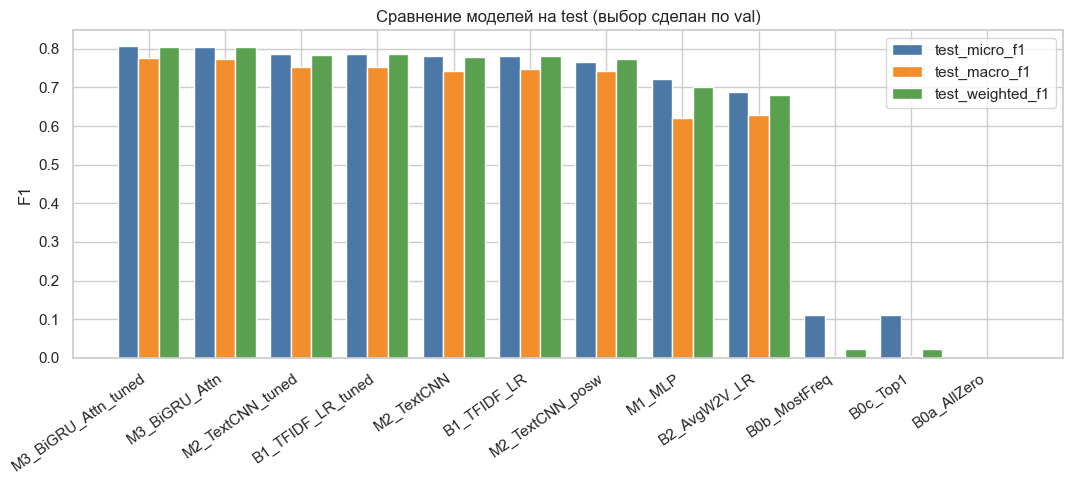

In [ ]:
# График: основная метрика (test_micro_f1) и вспомогательные
plt.figure(figsize=(11, 5))
mlist = ["test_micro_f1", "test_macro_f1", "test_weighted_f1"]
xn = np.arange(len(df_final))
for i, m in enumerate(mlist):
    plt.bar(xn + (i - 1) * 0.27, df_final[m].values, width=0.27,
            label=m, color=["#4C78A8", "#F28E2B", "#59A14F"][i])
plt.xticks(xn, df_final["model"].tolist(), rotation=35, ha="right")
plt.ylabel("F1"); plt.title("Сравнение моделей на test (выбор сделан по val)")
plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
hyp_tbl = df_final[df_final["model"].isin(
    [
        "B1_TFIDF_LR",
        "B1_TFIDF_LR_tuned",
        "B2_AvgW2V_LR",
        "M1_MLP",
        "M2_TextCNN",
        "M2_TextCNN_tuned",
        "M2_TextCNN_posw",
        "M3_BiGRU_Attn",
        "M3_BiGRU_Attn_tuned",
    ]
)][
    ["model", "val_micro_f1_tuned", "test_micro_f1", "test_macro_f1"]
].reset_index(drop=True)

hyp_tbl

,model,val_micro_f1_tuned,test_micro_f1,test_macro_f1
0,M3_BiGRU_Attn_tuned,0.8074,0.8072,0.7753
1,M3_BiGRU_Attn,0.8041,0.8049,0.7738
2,M2_TextCNN_tuned,0.7886,0.7861,0.7517
3,B1_TFIDF_LR_tuned,0.7879,0.7873,0.7536
4,M2_TextCNN,0.7831,0.7822,0.7427
5,B1_TFIDF_LR,0.7823,0.7822,0.7475
6,M2_TextCNN_posw,0.7644,0.7653,0.7437
7,M1_MLP,0.7235,0.7217,0.6206
8,B2_AvgW2V_LR,0.6894,0.6872,0.6282


**Аналитический вывод по сравнению моделей.**

1. `AvgW2V + LR` значительно уступает `TF-IDF + LR`: `0.6872` против `0.7822–0.7873` test micro-F1. Значит, простое усреднение word2vec-векторов теряет важную информацию о локальных терминах и их сочетаниях.
2. TextCNN с pretrained word2vec примерно выходит на уровень tuned TF-IDF, но на test немного уступает ему: `0.7861` против `0.7873`.
3. BiGRU + Attention заметно сильнее TextCNN и TF-IDF: tuned BiGRU получает `test_micro_f1 = 0.8072`.
4. Гипотеза о полезности связки «доменный word2vec + нейросеть» получает частичное подтверждение: лучшая нейросетевая модель даёт прирост около 0.02 micro-F1 относительно сильного TF-IDF baseline. Но нельзя утверждать, что word2vec сам по себе лучше TF-IDF, потому что слабый результат `AvgW2V + LR` показывает зависимость качества от архитектуры.
5. `pos_weight` не стал лучшим решением: он повышает акцент на положительных примерах, но ухудшает итоговый micro-F1.


---
## 19. Анализ ошибок

Для анализа ошибок берётся модель, выбранная по validation: **`M3_BiGRU_Attn_tuned`**. На test она использует threshold **0.36** и получает `test_micro_f1 = 0.8072`.

Анализ выполняется в трёх формах:

1. per-label precision/recall/F1 и support;
2. график зависимости per-label F1 от частоты метки;
3. конкретные примеры false positives и false negatives.

Цель анализа — не только показать среднее качество, но и понять, на каких типах рубрик модель ошибается.


In [ ]:
# Получаем предсказания лучшей модели на test
def get_best_test_predictions():
    name = best_name
    if name == "B1_TFIDF_LR":          return b1["prob_te"], b1["thr"]
    if name == "B1_TFIDF_LR_tuned":    return prob_te_b1t,   thr_b1t
    if name == "B2_AvgW2V_LR":         return prob_te_b2,    thr_b2
    if name.startswith("B0"):
        # Тривиальные не имеют осмысленных скоров
        if name == "B0a_AllZero":
            p = np.zeros_like(Y_test_final).astype(np.float32); return p, 0.5
        if name == "B0b_MostFreq":
            p = np.zeros_like(Y_test_final).astype(np.float32); p[:, mf_idx] = 1.0
            return p, 0.5
        if name.startswith("B0c"):
            p = np.zeros_like(Y_test_final).astype(np.float32); p[:, topk_idx] = 1.0
            return p, 0.5
    # Нейросеть — из чекпоинта
    ckpt = Path(CONFIG["models_dir"]) / f"best_{name}.pt"
    state = torch.load(ckpt, map_location=DEVICE)
    if name.startswith("M1_MLP"):              cls, kw = MLP, dict(hidden=256, dropout=0.4)
    elif name.startswith("M2_TextCNN_tuned"):  cls = TextCNN; kw = dict(n_filters=bp["n_filters"], dropout=bp["dropout"], kernel_sizes=(3,5,7))
    elif name.startswith("M2_TextCNN_posw"):   cls = TextCNN; kw = dict(n_filters=bp["n_filters"], dropout=bp["dropout"], kernel_sizes=(3,5,7))
    elif name.startswith("M2_TextCNN"):
        cls = TextCNN
        kw = dict(n_filters=96, dropout=0.4, kernel_sizes=(3, 5, 7))

    # ВАЖНО: tuned-ветка выше обычной M3
    elif name.startswith("M3_BiGRU_Attn_tuned"):
        cls = BiGRUAttn
        kw = dict(
            hidden=bp_m3["hidden"],
            dropout=bp_m3["dropout"],
        )

    elif name.startswith("M3_BiGRU_Attn"):
        cls = BiGRUAttn
        kw = dict(hidden=128, dropout=0.4)
    model = cls(emb_matrix_t, n_labels=len(WHITELIST), **kw).to(DEVICE)
    model.load_state_dict(state["state_dict"])
    crit = nn.BCEWithLogitsLoss()
    _, pr, _ = _epoch(model, DataLoader(test_ds, batch_size=64), None, crit)
    return pr, state["threshold"]

prob_best, thr_best = get_best_test_predictions()
pred_best = (prob_best >= thr_best).astype(np.int8)
print(f"Используем для анализа ошибок: {best_name} (thr={thr_best:.2f})")
print(f"Test micro-F1: "
      f"{f1_score(Y_test_final, pred_best, average='micro', zero_division=0):.4f}")

Используем для анализа ошибок: M3_BiGRU_Attn_tuned (thr=0.36)
Test micro-F1: 0.8072


In [ ]:
# Per-label метрики
per_label = pd.DataFrame({
    "label":     WHITELIST,
    "support":   Y_test_final.sum(0).astype(int),
    "precision": precision_score(Y_test_final, pred_best, average=None, zero_division=0),
    "recall":    recall_score(   Y_test_final, pred_best, average=None, zero_division=0),
    "f1":        f1_score(       Y_test_final, pred_best, average=None, zero_division=0),
}).sort_values("f1", ascending=False).reset_index(drop=True)
print("Топ-10 лучших меток по F1:")
print(per_label.head(10))
print("\nХудшие 10 меток:")
print(per_label.tail(10))

Топ-10 лучших меток по F1:
                         label  support  precision    recall        f1
0             Multiple Myeloma      835   0.992665  0.972455  0.982456
1         Diabetic Retinopathy      679   0.987692  0.945508  0.966140
2                Diabetic Foot      329   0.990196  0.920973  0.954331
3   Aortic Aneurysm, Abdominal      469   0.939394  0.925373  0.932331
4          Atrial Fibrillation     1762   0.915121  0.923950  0.919514
5                 Hypertension     3174   0.926205  0.889729  0.907601
6        Aortic Valve Stenosis      674   0.855615  0.949555  0.900141
7      Hypertension, Pulmonary      603   0.883013  0.913765  0.898126
8        Intracranial Aneurysm      569   0.887737  0.903339  0.895470
9  Peripheral Arterial Disease      562   0.932039  0.854093  0.891365

Худшие 10 меток:
                            label  support  precision    recall        f1
40           Arrhythmias, Cardiac      645   0.644345  0.671318  0.657555
41  Ventricular Dysfunctio

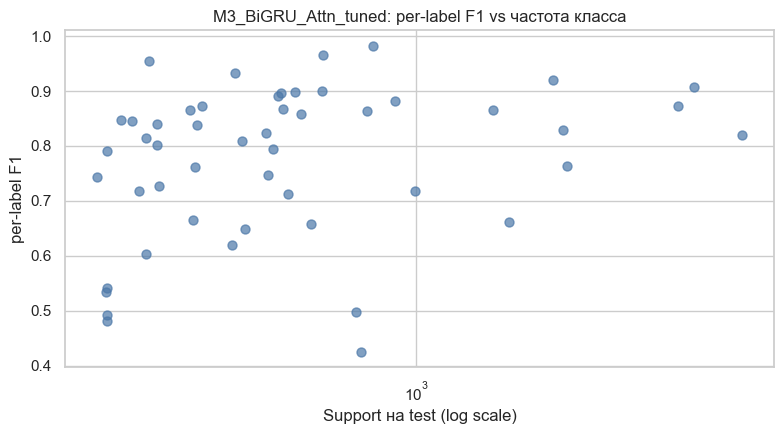

In [ ]:
# F1 vs support
plt.figure(figsize=(8, 4.5))
plt.scatter(per_label["support"], per_label["f1"], alpha=0.7, s=42, color="#4C78A8")
plt.xscale("log"); plt.xlabel("Support на test (log scale)")
plt.ylabel("per-label F1"); plt.title(f"{best_name}: per-label F1 vs частота класса")
plt.tight_layout(); plt.show()

In [ ]:
# Примеры false positives / false negatives
def fp_fn_examples(k=5):
    fp_out, fn_out = [], []
    for i in range(len(df_test)):
        true_set = set(np.where(Y_test_final[i] == 1)[0].tolist())
        pred_set = set(np.where(pred_best[i]    == 1)[0].tolist())
        fps = pred_set - true_set
        fns = true_set - pred_set
        if fps and len(fp_out) < k:
            j = max(fps, key=lambda j: prob_best[i, j])
            fp_out.append({"pmid": df_test.iloc[i]["pmid"],
                           "fp_label": WHITELIST[j], "prob": float(prob_best[i, j]),
                           "title": df_test.iloc[i]["title"][:120],
                           "true_labels": [WHITELIST[k] for k in true_set]})
        if fns and len(fn_out) < k:
            j = min(fns, key=lambda j: prob_best[i, j])
            fn_out.append({"pmid": df_test.iloc[i]["pmid"],
                           "fn_label": WHITELIST[j], "prob": float(prob_best[i, j]),
                           "title": df_test.iloc[i]["title"][:120],
                           "true_labels": [WHITELIST[k] for k in true_set]})
        if len(fp_out) >= k and len(fn_out) >= k:
            break
    return fp_out, fn_out

fps, fns = fp_fn_examples(5)
print("=== FALSE POSITIVES ===")
for r in fps: print(r); print()
print("\n=== FALSE NEGATIVES ===")
for r in fns: print(r); print()

=== FALSE POSITIVES ===
{'pmid': '30897587', 'fp_label': 'Brain Ischemia', 'prob': 0.517500102519989, 'title': 'Predictable Value of Functional Independence Measure Differs between Anterior and Posterior Circulation Ischemic Strokes', 'true_labels': ['Stroke']}

{'pmid': '30731463', 'fp_label': 'Cerebral Hemorrhage', 'prob': 0.7449520230293274, 'title': 'Intra-Arterial Thrombolysis Improves the Prognosis of Acute Ischemic Stroke Patients without Large Vessel Occlusion.', 'true_labels': ['Stroke', 'Brain Ischemia']}

{'pmid': '30684340', 'fp_label': 'Hypertension', 'prob': 0.8245118260383606, 'title': 'Effect of quercetin on the echocardiographic parameters of left ventricular diastolic function in patients with gout and', 'true_labels': ['Ventricular Dysfunction, Left']}

{'pmid': '30665216', 'fp_label': 'Stroke', 'prob': 0.6667073369026184, 'title': 'Carotid artery stenting without using any embolic protective device A single Centre experience.', 'true_labels': ['Carotid Stenosis']}



### Выводы по анализу ошибок M3_BiGRU_Attn_tuned

#### 1. Связь между support и качеством не является линейной

На графике `per-label F1 vs support` видно, что частота метки влияет на качество, но не объясняет его полностью. В целом метки с большим support чаще имеют высокий F1, потому что модель видит больше положительных примеров при обучении. Однако на графике есть важные исключения: некоторые достаточно частые метки имеют низкий F1, а часть среднечастотных меток классифицируется очень хорошо.

Это означает, что качество определяется не только числом примеров, но и **терминологической устойчивостью**, **специфичностью рубрики** и **пересечением с другими MeSH-дескрипторами**.

#### 2. Лучше всего классифицируются специфичные и терминологически устойчивые метки

Топ-10 лучших меток имеют высокий F1: например, `Multiple Myeloma` (`F1 = 0.9825`), `Diabetic Retinopathy` (`0.9661`), `Diabetic Foot` (`0.9543`), `Aortic Aneurysm, Abdominal` (`0.9323`), `Atrial Fibrillation` (`0.9195`), `Hypertension` (`0.9076`).

Общая закономерность: хорошо работают метки, у которых в заголовках и abstract обычно есть устойчивые диагностические формулировки. Например, `Atrial Fibrillation`, `Hypertension`, `Aortic Valve Stenosis`, `Peripheral Arterial Disease` часто прямо называются в тексте статьи. Поэтому модель получает сильный текстовый сигнал и уверенно отличает такие рубрики от остальных.

#### 3. Хуже всего работают общие, пересекающиеся и иерархически близкие рубрики

Худшие значения F1 получены для меток `Ischemic Stroke` (`F1 = 0.4249`), `Intracranial Hemorrhages` (`0.4810`), `Thromboembolism` (`0.4916`), `Heart Diseases` (`0.4971`), `Cerebrovascular Disorders` (`0.5346`), `Heart Valve Diseases` (`0.5410`).

Проблема состоит в том, что некоторые MeSH-дескрипторы близки между собой, пересекаются по контексту или находятся на разных уровнях обобщения. Например, `Heart Diseases` является широкой рубрикой, которая может пересекаться с более конкретными диагнозами. Аналогично, `Stroke`, `Ischemic Stroke`, `Brain Ischemia`, `Cerebrovascular Disorders`, `Cerebral Hemorrhage` и `Intracranial Hemorrhages` образуют семантически близкую группу цереброваскулярных состояний.

В flat multi-label постановке модель не знает явной иерархии MeSH и не получает правила вида: если статья относится к более конкретной рубрике, она может быть связана и с более общей. Поэтому часть ошибок возникает из-за отсутствия иерархической структуры в модели.

#### 4. Основной тип false positive — предсказание близкой, но не указанной MeSH-метки

False positive-примеры показывают, что модель часто добавляет тематически близкую метку, которой нет в gold-разметке статьи. Например:

- для статьи с истинной меткой `Stroke` модель добавляет `Brain Ischemia`;
- для статьи с `Stroke` и `Brain Ischemia` модель добавляет `Cerebral Hemorrhage`;
- для статьи про `Carotid Stenosis` модель добавляет `Stroke`;
- для статьи про large vessel occlusion модель добавляет `Ischemic Stroke`.

Это типичная ошибка для multilabel MeSH-классификации: модель распознаёт правильную тематическую область, но не всегда точно воспроизводит конкретный набор дескрипторов, назначенный индексатором. В таких случаях false positive может быть медицински близким к теме статьи, но формально считается ошибкой, потому что отсутствует в целевой MeSH-разметке.

Особенно заметна группа ошибок вокруг цереброваскулярных терминов. Это показывает, что модель хорошо улавливает общий контекст инсульта, ишемии и сосудистых нарушений, но ей трудно различать точные границы между близкими дескрипторами.

#### 5. Основной тип false negative — пропуск специфической метки при косвенном текстовом сигнале

False negative-примеры показывают обратную проблему: модель иногда не предсказывает правильную метку, если она выражена в тексте косвенно или конкурирует с более частыми соседними рубриками.

Например:

- `Cerebral Hemorrhage` не предсказана для статьи о parenchymal hemorrhage after burr hole drainage;
- `Ventricular Dysfunction, Left` не предсказана для статьи о false positive cardiotoxicity events;
- `Brain Ischemia` не предсказана для статьи, где основной сигнал связан с poststroke depression;
- `Cardiotoxicity` не предсказана для статьи о heart failure after Adriamycin-induced damage.

В этих случаях название статьи не всегда содержит точную формулировку MeSH-метки. Модель должна вывести рубрику по клиническому контексту, а это сложнее, чем распознать прямое совпадение термина.

#### 6. Precision/recall по худшим меткам показывает разные типы проблем

У некоторых слабых меток главная проблема — низкий recall. Например, `Intracranial Hemorrhages` имеет precision `0.7983`, но recall `0.3442`. Это означает, что когда модель предсказывает эту метку, она часто права, но пропускает большую часть настоящих случаев.

У `Ischemic Stroke` ситуация другая: precision `0.4152`, recall `0.4351`, то есть модель одновременно часто ошибочно добавляет эту метку и часто пропускает её. Это указывает на сильное пересечение с соседними рубриками, прежде всего `Stroke`, `Brain Ischemia` и другими цереброваскулярными дескрипторами.

У широких меток вроде `Heart Diseases` низкие precision и recall связаны с тем, что они слишком общие. Такие рубрики трудно отличать от более конкретных диагнозов, особенно если статья размечена несколькими MeSH-дескрипторами разного уровня.

#### 7. Главный insight: модель лучше распознаёт терминологически конкретные болезни, чем границы MeSH-онтологии

Итоговая закономерность состоит в следующем: модель хорошо работает там, где рубрика имеет устойчивый и явно выраженный текстовый маркер. Она хуже работает там, где требуется различать близкие MeSH-дескрипторы, общие и частные понятия, а также медицински смежные состояния.

Это ограничение связано не только с архитектурой модели, но и с самой постановкой задачи. MeSH-разметка отражает экспертное индексирование статьи, а не простое наличие слов в abstract. Поэтому модель может выбрать медицински близкую метку, но получить ошибку относительно gold-разметки.

#### 8. Вывод

Анализ ошибок подтверждает, что **M3_BiGRU_Attn_tuned** является сильной моделью для multilabel-рубрицирования, но её ошибки концентрируются в семантически близких группах labels. Особенно сложными остаются цереброваскулярные, тромботические и широкие сердечно-сосудистые рубрики.

В целом модель не просто угадывает частые метки, а действительно выделяет медицинские темы из текста. Однако flat multilabel-подход ограничен тем, что не моделирует онтологические связи между MeSH-дескрипторами.


---
## 20. Заключение

### 20.1. Что было сделано

В работе построен полный экспериментальный пайплайн для рубрицирования англоязычных PubMed-аннотаций по MeSH-дескрипторам cardiovascular-направления.

Ключевые этапы:

1. Собран и использован кэшированный PubMed XML-корпус за **2018–2024** годы: **495 137** raw-записей и **482 061** записей после базовой очистки.
2. `IndexingMethod` извлечён на уровне `MedlineCitation` и использован для разделения корпуса: **279 985** supervised-записей (`manual` + `curated`) и расширенный unsupervised-корпус для word2vec.
3. Пространство labels построено через официальный MeSH tree file `mtrees.bin`: **469** C14-потомков в дереве, **462** C14-метки фактически встретились в supervised-корпусе.
4. Выполнен multilabel iterative split. После W50-whitelist итоговые размеры: **143 283 train**, **30 388 validation**, **30 265 test**.
5. Обучены CBOW и Skip-gram word2vec на **421 408** документах без validation/test PMID. По downstream validation-F1 выбран **CBOW** (`0.6894` против `0.6704`).
6. Реализованы и сравнены baseline-модели, TF-IDF + LR, AvgW2V + LR, MLP, TextCNN и BiGRU + Attention.
7. Выполнен holdout-подбор TF-IDF + LR и Optuna-подбор TextCNN и BiGRU.
8. Лучшая модель по validation — **`M3_BiGRU_Attn_tuned`** с `val_micro_f1_tuned = 0.8074`.
9. Финальная test-оценка лучшей модели: `test_micro_f1 = 0.8072`, `test_macro_f1 = 0.7753`, `test_weighted_f1 = 0.8050`, `micro_precision = 0.8189`, `micro_recall = 0.7958`.
10. Проведён анализ ошибок по per-label метрикам, support и конкретным FP/FN-примерам.

### 20.2. Ответ на гипотезу

Связка **доменный word2vec + BiGRU + Attention** показала лучший результат и превзошла сильный tuned TF-IDF baseline:

$$
\Delta_{\mathrm{microF1}} =
0.8072 - 0.7873 \approx 0.0199
$$

Это означает умеренный прирост качества в данном эксперименте. Однако результат нужно интерпретировать осторожно:

- `AvgW2V + LR` существенно проиграл TF-IDF (`0.6872` против `0.7873` test micro-F1);
- TextCNN с word2vec оказался примерно на уровне TF-IDF, но не лучше его на test;
- лучший результат дала именно последовательностная архитектура BiGRU + Attention.
- без повторных запусков с разными seed этот прирост следует интерпретировать как результат данного запуска, а не как статистически подтверждённое превосходство.

Следовательно, работа не доказывает, что word2vec как простое документное представление лучше TF-IDF. Более корректный вывод: **pretrained domain word2vec полезен в составе последовательностной нейросетевой модели, но его вклад смешан с вкладом архитектуры**.

### 20.3. Ограничения работы

1. `max_seq_len=256` обрезает **34.51%** supervised-документов, поэтому часть контекста теряется.
2. C14 — широкая MeSH-ветвь; выбранные labels включают не только классические кардиологические диагнозы, но и сосудистые, диабетические, цереброваскулярные и смежные состояния.
3. Используется flat multi-label classification. Иерархия MeSH не моделируется явно, из-за чего близкие дескрипторы могут конкурировать друг с другом.

### 20.4. Что можно улучшить дальше

- Провести абляцию эмбеддингов: random init, frozen word2vec, fine-tuned word2vec.
- Проверить большие `max_seq_len` (`384`, `512`) и оценить цену/выигрыш.
- Добавить BioWordVec, PubMedBERT или BioBERT как внешние biomedical baselines.
- Использовать иерархию MeSH в loss или post-processing.
- Проверить W100 как основной target space при достаточном объёме положительных примеров.

### 20.5. Использованные источники

1. Gensim Documentation. **models.word2vec — Word2Vec embeddings**. Используется как практический источник по реализации Word2Vec в библиотеке `gensim`. (https://radimrehurek.com/gensim/models/word2vec.html)

2. NCBI. **Entrez Programming Utilities Help**. Используется для описания E-utilities, `esearch`, `efetch`, `usehistory`, ограничений выгрузки и программного доступа к PubMed. (https://www.ncbi.nlm.nih.gov/books/NBK25501/)

3. National Library of Medicine. **Download MeSH Data**. Используется как источник по официальным MeSH-файлам, включая Descriptor, Qualifier, SCR и годовые версии MeSH. (https://www.nlm.nih.gov/databases/download/mesh.html)

4. National Library of Medicine. **Guide to Using the MeSH FTP Download Site**. Используется для обоснования загрузки MeSH tree-файлов и работы с `mtrees*.bin`. (https://www.nlm.nih.gov/mesh/MeSH_FTP_Guide.html)

5. National Library of Medicine. **Use of MeSH in Indexing**. Используется для объяснения назначения MeSH-разметки в MEDLINE/PubMed и перехода к automated indexing. (https://www.nlm.nih.gov/mesh/intro_indexing.html)

6. National Library of Medicine. **Automated Indexing FAQs** / **MTIX: the Next-Generation Algorithm for Automated Indexing**. Используется для объяснения `IndexingMethod`, автоматической индексации MEDLINE и ограничений использования automated labels как supervised-разметки. (https://support.nlm.nih.gov/kbArticle/?pn=KA-05326)

7. scikit-learn Documentation. **TfidfVectorizer, LogisticRegression, OneVsRestClassifier, metrics**. Используется для TF-IDF baseline, One-vs-Rest multilabel-классификации и расчёта метрик `F1`, `average precision`, `LRAP`. (https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)

8. PyTorch Documentation. **Embedding, GRU, MultiheadAttention, BCEWithLogitsLoss**. Используется для описания embedding-слоя, BiGRU, attention-механизма и `pos_weight` в multilabel loss. (https://docs.pytorch.org/docs/stable/generated/torch.nn.Embedding.html)

9. Optuna Documentation. **TPESampler**. Используется для описания автоматического подбора гиперпараметров методом TPE. (https://optuna.readthedocs.io/en/stable/reference/samplers/generated/optuna.samplers.TPESampler.html)
